# 更新后的分子动力学指标与 FEL 完整绘图

本 notebook 统一绘制 GSK3β–Rg1、CASP9–Rg1、BACE1–Rg1 的 RMSD、RMSF、Rg、SASA、蛋白–配体氢键，以及 RMSD–Rg 和 PC1–PC2 的 FEL 2D/3D 图。

使用已核查的数据包：RMSD/RMSF 为几何重算结果，其余三项为核查通过的原始数据。保留参考代码的分面顺序、体系配色、统计项目及 3D 曲面与底部等高线样式，修正旧数据路径、参考结构、残基编号和显示范围的问题。

从上到下运行全部单元格。通常只需修改第 2 节的参数。所有图片和绘图源数据保存到本 notebook 同目录下的 `更新后图片结果`。代码不运行新的 MD，也不会改动输入数据。


## 1. 依赖与路径

需要 Python、numpy、pandas、scipy、matplotlib、IPython、pillow。依赖缺失时，可取消下一单元格第一行的注释安装后重启内核。

路径默认自动定位当前 QC 文件夹；如果 notebook 被移到其他位置，在第 2 节显式设置 `QC_DIR_OVERRIDE`。


In [3]:
# %pip install numpy pandas scipy matplotlib ipython pillow
from pathlib import Path
from datetime import datetime
from io import BytesIO
import hashlib
import json
import platform
import warnings

import numpy as np
import pandas as pd
import scipy
from scipy.ndimage import gaussian_filter
import matplotlib as mpl
mpl.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from IPython.display import display, Image, Markdown

print("Python:", platform.python_version())
print("numpy / pandas / scipy / matplotlib:", np.__version__, pd.__version__, scipy.__version__, mpl.__version__)


Python: 3.14.2
numpy / pandas / scipy / matplotlib: 2.4.4 3.0.2 1.17.1 3.10.8


## 2. 集中参数

- `TIME_AXIS_UNIT` 控制指标图的时间轴，默认统一为 ns，读取时仍严格遵守 CSV 的原单位。
- RMSF 的 x 为模型 Cα 序号，不是原始 PDB 残基号；原链号、残基号、插入码另存身份表，按断开的片段分别画线。
- `FEL_START_NS/FEL_END_NS` 只控制 FEL 的统计时间窗。预计算 RMSF 仍对应完整 0–100 ns，改变 FEL 时间窗不会重新计算 RMSF。
- 默认 FEL 为原始计数、无平滑。需要参考图的平滑外观时，可将指定坐标的 `FEL_SIGMA` 改为 1.2；原始空网格仍不绘制，未平滑估计仍导出。
- 默认能量范围自动覆盖实际已采样区域；设定过小的上限会报错，避免静默截断。


In [4]:
QC_DIR_OVERRIDE = None  # Example: Path(r"C:\...\MD_QC_20261110")
SYSTEMS = ("GSK3beta-Rg1", "CASP9-Rg1", "BACE1-Rg1")
SYSTEM_LABELS = {"GSK3beta-Rg1": "GSK3β–Rg1", "CASP9-Rg1": "CASP9–Rg1", "BACE1-Rg1": "BACE1–Rg1"}
COLORS = {"GSK3beta-Rg1": "#D62728", "CASP9-Rg1": "#228B22", "BACE1-Rg1": "#1F77B4"}
TIME_AXIS_UNIT = "ns"  # "ns" or "ps"
VERIFY_INPUT_HASHES = True
EXPECTED_FRAMES = 10001
TAIL_START_NS = 70.0  # Descriptive terminal window, not a claim of equilibrium.

LINE_FONT = "Times New Roman"
FEL_FONT = "Arial"
LINE_WIDTH = 1.0
HBOND_LINE_WIDTH = 0.55
FIGSIZE_METRIC = (6.4, 3.7)
DPI = 600
EXPORT_FORMATS = ("png", "pdf", "svg")
SHOW_SINGLE_METRICS = True
SHOW_OVERVIEWS = True
SHOW_FEL = True

FEL_MODES = ("RMSD_Rg", "PC1_PC2")
FEL_TEMPERATURE_K = 300.0
FEL_START_NS = 0.0
FEL_END_NS = None
FEL_BINS = {"RMSD_Rg": (50, 50), "PC1_PC2": (50, 50)}
FEL_SIGMA = {"RMSD_Rg": 0.0, "PC1_PC2": 0.0}
FEL_MIN_BIN_COUNT = 1
FEL_ENERGY_MAX = None
FEL_COLORMAP = "jet"  # Matches the supplied template; "viridis" is also available.
FEL_ELEVATION = 28
FEL_AZIMUTH = -135
FEL_FLOOR_Z = -1.2
FEL_FIGSIZE_2D = (7.6, 6.0)
FEL_FIGSIZE_3D = (10.0, 7.8)
PCA_FILE_OVERRIDES = {}  # Optional: {"CASP9-Rg1": Path(r"...\proj.xvg")}


def find_qc_directory(override):
    if override is not None:
        candidates = [Path(override).expanduser().resolve()]
    else:
        here = Path.cwd().resolve()
        candidates = []
        for base in (here, *here.parents):
            candidates.extend((base, base / "MD_QC_20261110", base / "模拟结果" / "MD_QC_20261110"))
    for candidate in candidates:
        if (candidate / "additional_metrics" / "verified_plot_data").is_dir():
            return candidate
    raise FileNotFoundError("未找到已核查数据包，请在 QC_DIR_OVERRIDE 中指定 MD_QC_20261110 文件夹。")


QC_DIR = find_qc_directory(QC_DIR_OVERRIDE)
AUDIT_DIR = QC_DIR / "additional_metrics"
DATA_DIR = AUDIT_DIR / "verified_plot_data"
OUTPUT_DIR = QC_DIR / "更新后图片结果"
OUT = {
    "single": OUTPUT_DIR / "01_单项指标",
    "overview": OUTPUT_DIR / "02_指标组合图",
    "fel2d": OUTPUT_DIR / "03_FEL_2D",
    "fel3d": OUTPUT_DIR / "04_FEL_3D",
    "data": OUTPUT_DIR / "05_绘图数据与统计",
    "logs": OUTPUT_DIR / "06_运行记录",
}
for directory in OUT.values():
    directory.mkdir(parents=True, exist_ok=True)
if TIME_AXIS_UNIT not in ("ns", "ps"):
    raise ValueError("TIME_AXIS_UNIT must be 'ns' or 'ps'")
if FEL_TEMPERATURE_K <= 0 or FEL_START_NS < 0 or (FEL_END_NS is not None and FEL_END_NS <= FEL_START_NS):
    raise ValueError("Invalid FEL temperature or time window")
if not isinstance(FEL_MIN_BIN_COUNT, int) or FEL_MIN_BIN_COUNT < 1:
    raise ValueError("FEL_MIN_BIN_COUNT must be an integer >= 1")

mpl.rcParams.update({
    "font.family": LINE_FONT, "font.size": 11, "axes.labelsize": 12,
    "axes.linewidth": 1.0, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.unicode_minus": False, "pdf.fonttype": 42, "svg.fonttype": "none",
    "savefig.facecolor": "white", "figure.facecolor": "white", "legend.frameon": False,
})
ARTIFACTS = {}
INPUT_FILES = {}
FIGURE_RECORDS = {}
RUN_STARTED_AT = datetime.now().astimezone().isoformat()
print("数据目录:", DATA_DIR)
print("输出目录:", OUTPUT_DIR)


数据目录: C:\Users\zengh\Desktop\生信文章\shengxin\文章二\分子动力学模拟\模拟结果\MD_QC_20261110\additional_metrics\verified_plot_data
输出目录: C:\Users\zengh\Desktop\生信文章\shengxin\文章二\分子动力学模拟\模拟结果\MD_QC_20261110\更新后图片结果


## 3. 输入完整性、单位和残基身份

本节核查 15 个 panel CSV、3 个残基身份表及数据包校验值。时间轴只进行 ps/ns 换算，不平移 RMSD，不缩放指标值，不删除极值。校验失败时立即停止，避免用旧数据生成图件。


In [5]:
METRICS = ("RMSD", "RMSF", "H-bond_count", "Radius_of_gyration", "SASA")
METRIC_LABELS = {"RMSD": "RMSD", "RMSF": "RMSF", "H-bond_count": "H-bonds", "Radius_of_gyration": "Rg", "SASA": "SASA"}
Y_LABELS = {"RMSD": "RMSD (nm)", "RMSF": "RMSF (nm)", "H-bond_count": "Number of H-bonds", "Radius_of_gyration": "Rg (nm)", "SASA": "SASA (nm$^2$)"}
VALUE_UNITS = {"RMSD": "nm", "RMSF": "nm", "H-bond_count": "count", "Radius_of_gyration": "nm", "SASA": "nm^2"}
PANEL_LETTERS = {metric: dict(zip(SYSTEMS, letters)) for metric, letters in zip(METRICS, ("ABC", "DEF", "GHI", "JKL", "MNO"))}


def record_input(path):
    path = Path(path).resolve()
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    INPUT_FILES[str(path)] = {"sha256": digest, "bytes": path.stat().st_size}
    return digest


def save_csv(frame, path):
    path = Path(path)
    frame.to_csv(path, index=False, encoding="utf-8-sig")
    ARTIFACTS[str(path)] = {"type": "csv", "bytes": path.stat().st_size}


manifest_path = AUDIT_DIR / "DELIVERY_VERIFICATION.json"
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
expected_hashes = {row["path"]: row["sha256"] for row in manifest["files"]}
record_input(manifest_path)
audit_path = AUDIT_DIR / "all_metric_audit.json"
AUDIT = json.loads(audit_path.read_text(encoding="utf-8"))
record_input(audit_path)
DATA, IDENTITIES, INPUT_CHECKS = {}, {}, []

for system in SYSTEMS:
    identity_path = DATA_DIR / f"{system}_residue_identity.csv"
    identity = pd.read_csv(identity_path, keep_default_na=False)
    digest = record_input(identity_path)
    if VERIFY_INPUT_HASHES and digest != expected_hashes[identity_path.relative_to(AUDIT_DIR).as_posix()]:
        raise ValueError(f"Residue identity checksum mismatch: {system}")
    IDENTITIES[system] = identity
    for metric in METRICS:
        matches = list(DATA_DIR.glob(f"panel_*_{metric}_{system}.csv"))
        if len(matches) != 1:
            raise ValueError(f"Expected one {system} {metric} file, found {len(matches)}")
        path = matches[0]
        digest = record_input(path)
        if VERIFY_INPUT_HASHES and digest != expected_hashes[path.relative_to(AUDIT_DIR).as_posix()]:
            raise ValueError(f"Input checksum mismatch: {path.name}")
        frame = pd.read_csv(path)
        if not {"x", "value", "x_unit", "value_unit", "panel"}.issubset(frame.columns):
            raise ValueError(f"Missing required columns: {path.name}")
        if not np.isfinite(frame[["x", "value"]].to_numpy(dtype=float)).all() or (frame.value < 0).any():
            raise ValueError(f"Non-finite or negative metric values: {path.name}")
        if not frame.value_unit.eq(VALUE_UNITS[metric]).all():
            raise ValueError(f"Unexpected value unit: {path.name}")
        if not frame.panel.eq(PANEL_LETTERS[metric][system]).all():
            raise ValueError(f"Unexpected panel mapping: {path.name}")
        if metric == "RMSF":
            if not frame.x_unit.eq("model_CA_index").all() or len(frame) != len(identity):
                raise ValueError(f"Ambiguous RMSF index or identity length: {system}")
            np.testing.assert_array_equal(frame.x, identity.model_ca_index)
            np.testing.assert_array_equal(frame.x, np.arange(1, len(frame) + 1))
            np.testing.assert_allclose(frame.value, identity.rmsf_corrected_gromacs_nm, atol=1e-8)
        else:
            units = frame.x_unit.unique().tolist()
            if len(units) != 1 or units[0] not in ("ps", "ns"):
                raise ValueError(f"Unexpected time unit: {path.name}")
            frame["time_ns"] = np.round(frame.x * (0.001 if units[0] == "ps" else 1.0), 8)
            if len(frame) != EXPECTED_FRAMES or not np.all(np.diff(frame.time_ns) > 0):
                raise ValueError(f"Unexpected frame count or time order: {path.name}")
            np.testing.assert_allclose(frame.time_ns, np.linspace(0, 100, EXPECTED_FRAMES), atol=1e-6)
        if metric == "H-bond_count":
            np.testing.assert_allclose(frame.value, np.round(frame.value), atol=1e-8)
        DATA[(system, metric)] = frame
        INPUT_CHECKS.append({"system": system, "metric": METRIC_LABELS[metric], "rows": len(frame),
                             "input_x_unit": frame.x_unit.iloc[0], "value_unit": VALUE_UNITS[metric],
                             "checksum_checked": VERIFY_INPUT_HASHES, "file": path.name})

input_checks = pd.DataFrame(INPUT_CHECKS)
save_csv(input_checks, OUT["logs"] / "input_checks.csv")
for system, identity in IDENTITIES.items():
    save_csv(identity, OUT["data"] / f"{system}_residue_identity.csv")
display(input_checks)
print("通过：15 个指标文件及 3 个残基身份表。")


,system,metric,rows,input_x_unit,value_unit,checksum_checked,file
0,GSK3beta-Rg1,RMSD,10001,ns,nm,True,panel_A_RMSD_GSK3beta-Rg1.csv
1,GSK3beta-Rg1,RMSF,692,model_CA_index,nm,True,panel_D_RMSF_GSK3beta-Rg1.csv
2,GSK3beta-Rg1,H-bonds,10001,ps,count,True,panel_G_H-bond_count_GSK3beta-Rg1.csv
3,GSK3beta-Rg1,Rg,10001,ps,nm,True,panel_J_Radius_of_gyration_GSK3beta-Rg1.csv
4,GSK3beta-Rg1,SASA,10001,ps,nm^2,True,panel_M_SASA_GSK3beta-Rg1.csv
5,CASP9-Rg1,RMSD,10001,ns,nm,True,panel_B_RMSD_CASP9-Rg1.csv
6,CASP9-Rg1,RMSF,230,model_CA_index,nm,True,panel_E_RMSF_CASP9-Rg1.csv
7,CASP9-Rg1,H-bonds,10001,ps,count,True,panel_H_H-bond_count_CASP9-Rg1.csv
8,CASP9-Rg1,Rg,10001,ps,nm,True,panel_K_Radius_of_gyration_CASP9-Rg1.csv
9,CASP9-Rg1,SASA,10001,ps,nm^2,True,panel_N_SASA_CASP9-Rg1.csv


通过：15 个指标文件及 3 个残基身份表。


## 4. 描述统计与清洁绘图数据

统计项目参考原 `analyze_md.py`：样本数、均值、标准差、最小值、最大值、中位数。这里使用样本标准差 `ddof=1`。

时间指标的 SD 表示同一轨迹内的时间波动；RMSF 汇总的 SD 表示不同残基 RMSF 值的离散程度。二者均不代表独立模拟之间的误差。70–100 ns 仅输出为末段描述，不命名为已平衡区间。


In [6]:
def describe_values(values):
    values = np.asarray(values, dtype=float)
    return {"n_points": len(values), "mean": float(values.mean()), "sd_ddof1": float(values.std(ddof=1)),
            "min": float(values.min()), "max": float(values.max()), "median": float(np.median(values))}


summary_rows, terminal_rows = [], []
for system in SYSTEMS:
    for metric in METRICS:
        frame = DATA[(system, metric)]
        summary_rows.append({"system": system, "metric": METRIC_LABELS[metric], "unit": VALUE_UNITS[metric],
            "spread_across": "residues" if metric == "RMSF" else "trajectory_frames", "independent_runs": 1,
            **describe_values(frame.value)})
        if metric == "RMSF":
            cleaned = IDENTITIES[system][["model_ca_index", "segid", "source_chain", "source_resid", "source_icode", "source_resname"]].copy()
            cleaned["RMSF_nm"] = frame.value.to_numpy()
        else:
            cleaned = pd.DataFrame({"time_ns": frame.time_ns, "value": frame.value, "value_unit": VALUE_UNITS[metric]})
            tail = frame.loc[frame.time_ns >= TAIL_START_NS]
            if len(tail) < 2:
                raise ValueError("The requested terminal window has fewer than two frames")
            terminal_rows.append({"system": system, "metric": METRIC_LABELS[metric], "unit": VALUE_UNITS[metric],
                "start_ns": float(tail.time_ns.iloc[0]), "end_ns": float(tail.time_ns.iloc[-1]), **describe_values(tail.value)})
        save_csv(cleaned, OUT["data"] / f"{system}_{METRIC_LABELS[metric]}_source.csv")

summary = pd.DataFrame(summary_rows)
terminal_summary = pd.DataFrame(terminal_rows)
save_csv(summary, OUT["data"] / "summary_full_trajectory.csv")
save_csv(terminal_summary, OUT["data"] / "summary_terminal_window.csv")
display(summary.round(5))


,system,metric,unit,spread_across,independent_runs,n_points,mean,sd_ddof1,min,max,median
0,GSK3beta-Rg1,RMSD,nm,trajectory_frames,1,10001,0.23279,0.03480,0.11007,0.35977,0.23384
1,GSK3beta-Rg1,RMSF,nm,residues,1,692,0.11030,0.08373,0.04250,0.85150,0.08780
2,GSK3beta-Rg1,H-bonds,count,trajectory_frames,1,10001,1.94751,1.12772,0.00000,8.00000,2.00000
3,GSK3beta-Rg1,Rg,nm,trajectory_frames,1,10001,2.72822,0.01067,2.69128,2.76793,2.72847
4,GSK3beta-Rg1,SASA,nm^2,trajectory_frames,1,10001,337.94539,3.56639,324.25600,351.48700,337.91600
5,CASP9-Rg1,RMSD,nm,trajectory_frames,1,10001,0.35132,0.08323,0.11136,0.53928,0.36164
6,CASP9-Rg1,RMSF,nm,residues,1,230,0.11961,0.15818,0.03980,1.31800,0.08045
7,CASP9-Rg1,H-bonds,count,trajectory_frames,1,10001,3.92551,1.22685,0.00000,9.00000,4.00000
8,CASP9-Rg1,Rg,nm,trajectory_frames,1,10001,1.73036,0.01296,1.69909,1.80617,1.72844
9,CASP9-Rg1,SASA,nm^2,trajectory_frames,1,10001,115.96688,2.38734,107.28900,125.03200,115.98700


## 5. 五类指标的单图和组合图

面板保留 A–O 编号：A–C RMSD，D–F RMSF，G–I 氢键，J–L Rg，M–O SASA。默认显示全部数据范围，不对原始曲线平滑。

RMSF 按真实片段分开绘制，GSK3β 的两条链通过实线/虚线区分。其 x 为模型顺序，原结构身份见已导出的 `residue_identity.csv`。SASA 的定义是蛋白单独 SASA，未计入 Rg1 的表面遮挡。Rg/SASA 的绝对值不可用于给不同大小或不同链数的蛋白直接排稳定性名次。


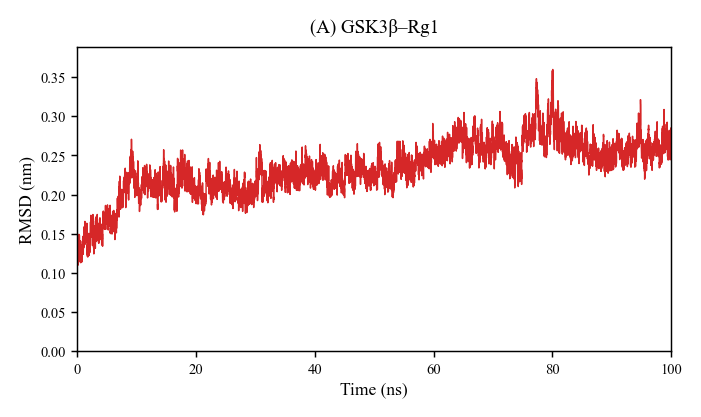

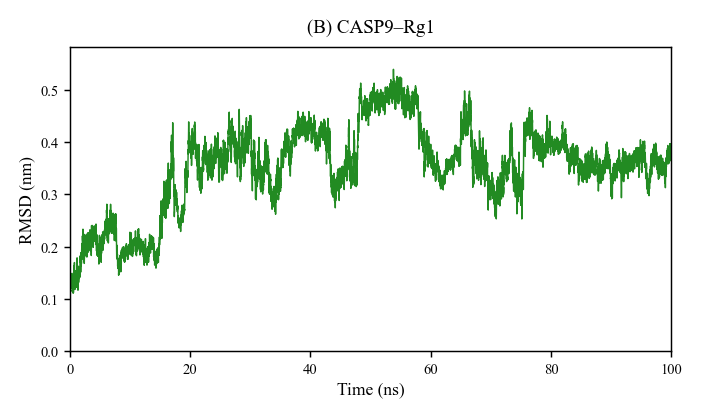

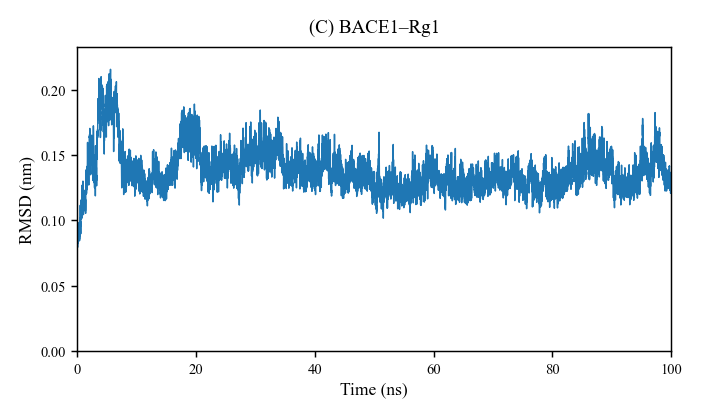

完成单项图：RMSD，3 个体系。


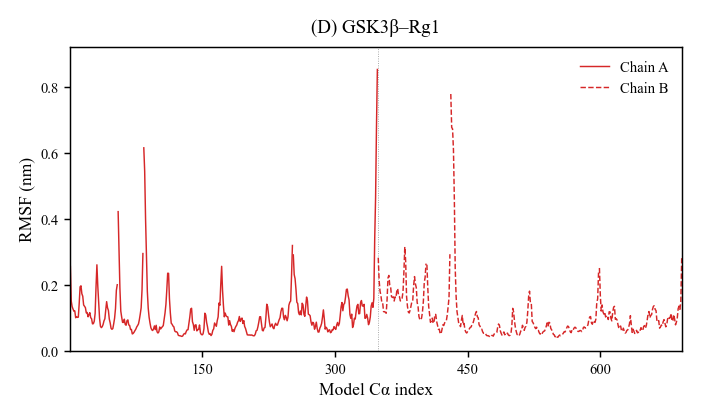

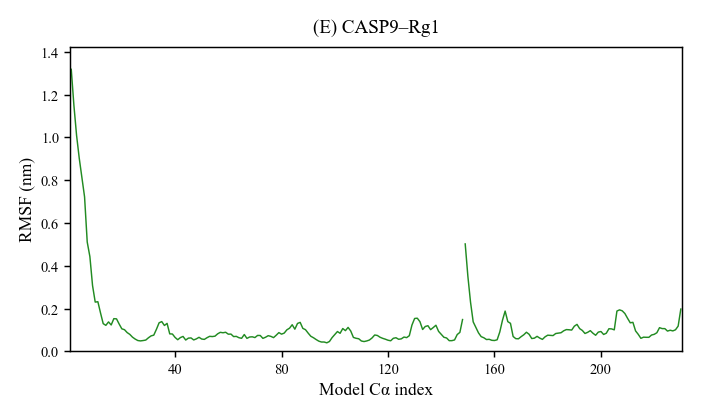

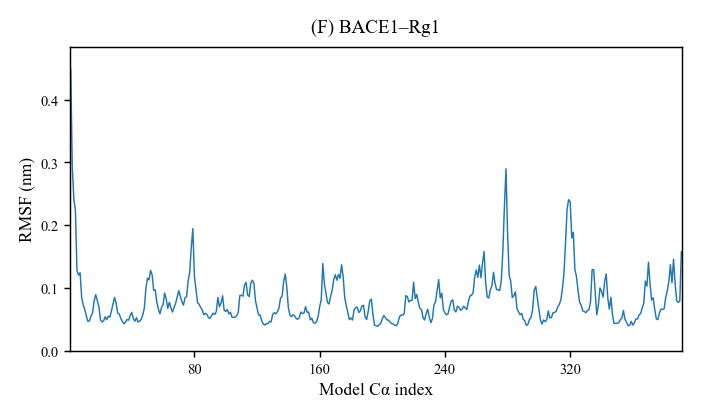

完成单项图：RMSF，3 个体系。


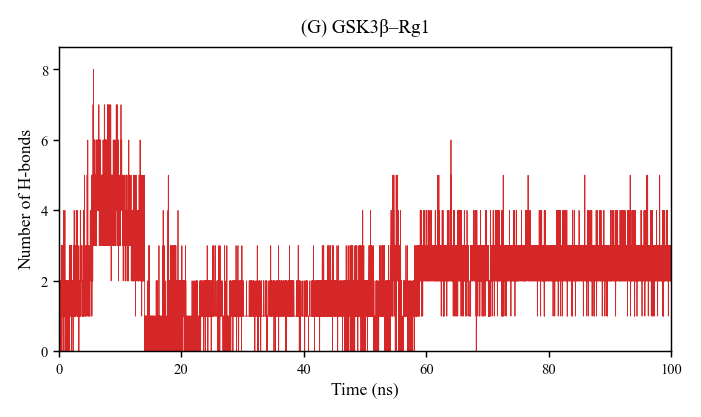

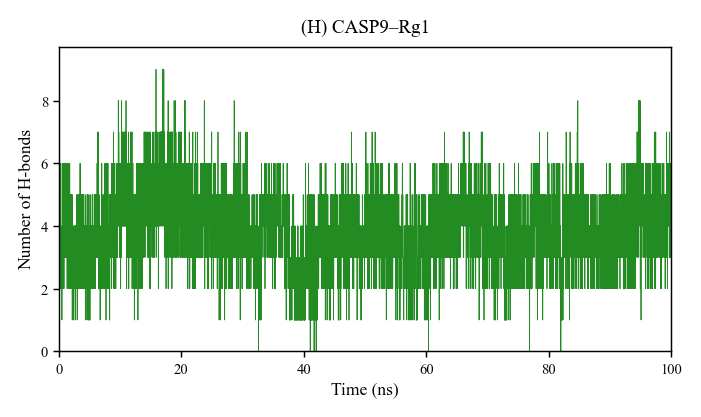

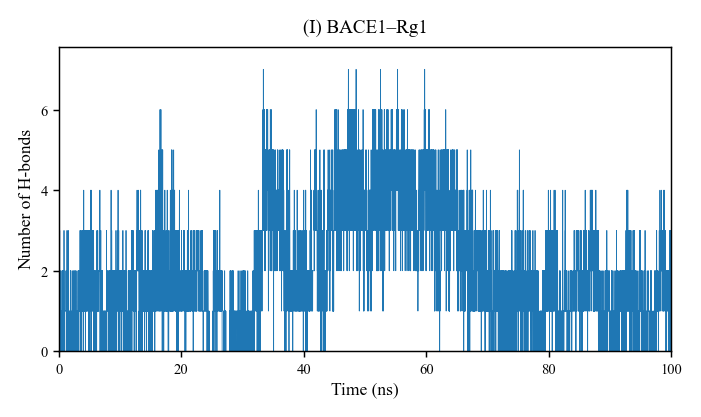

完成单项图：H-bonds，3 个体系。


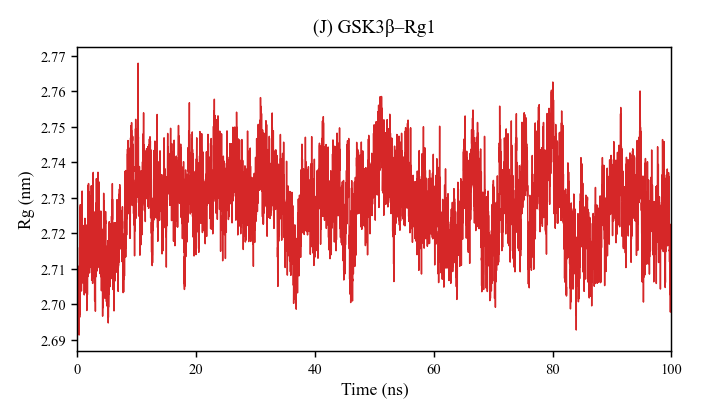

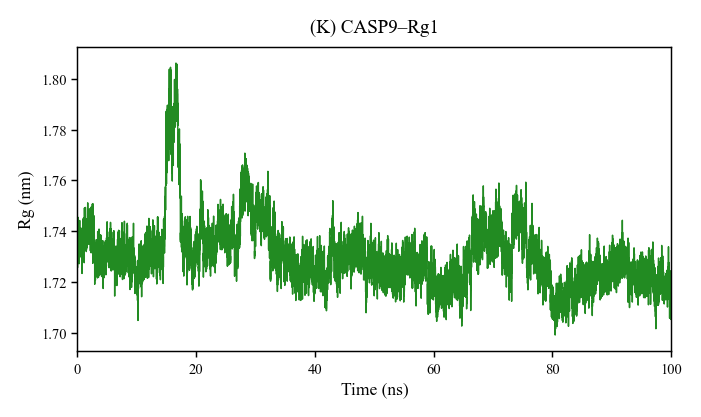

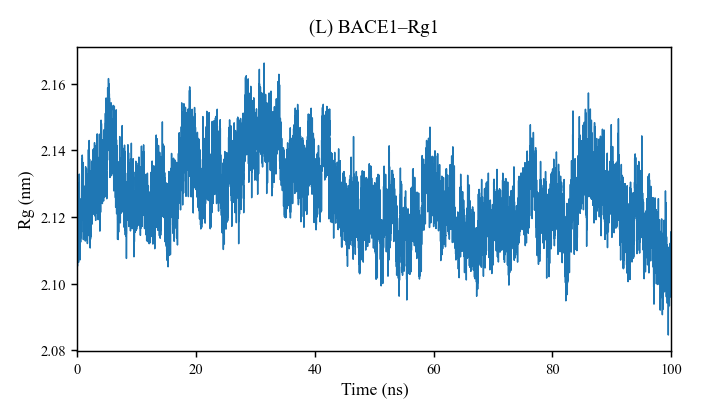

完成单项图：Rg，3 个体系。


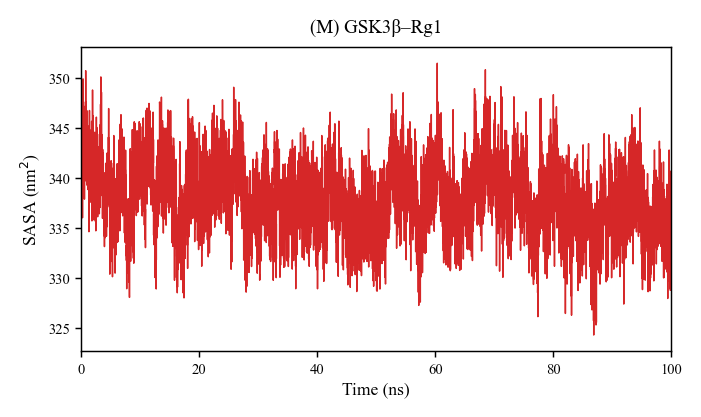

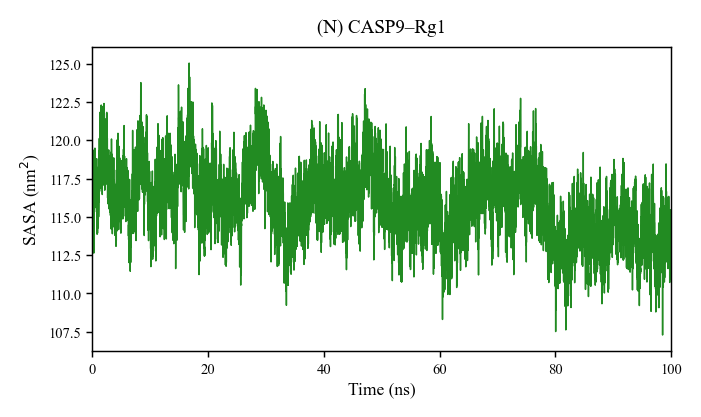

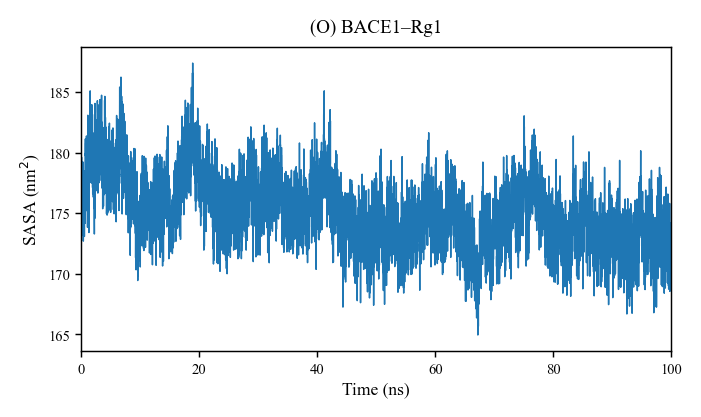

完成单项图：SASA，3 个体系。


In [7]:
def save_figure(figure, directory, stem, preview=False):
    extras = [axis.zaxis.label for axis in figure.axes if hasattr(axis, "zaxis")]
    for extension in EXPORT_FORMATS:
        path = directory / f"{stem}.{extension}"
        options = {"dpi": DPI, "bbox_inches": "tight", "pad_inches": 0.22}
        if extras:
            options["bbox_extra_artists"] = extras
        figure.savefig(path, **options)
        ARTIFACTS[str(path)] = {"type": extension, "bytes": path.stat().st_size}
    FIGURE_RECORDS[stem] = {"directory": directory.relative_to(OUTPUT_DIR).as_posix(),
                            "formats": list(EXPORT_FORMATS)}
    if preview:
        buffer = BytesIO()
        figure.savefig(buffer, format="png", dpi=105, bbox_inches="tight", pad_inches=0.18)
        display(Image(data=buffer.getvalue()))
    plt.close(figure)


def draw_metric(axis, system, metric, compact=False, panel_letter=True):
    frame = DATA[(system, metric)]
    color = COLORS[system]
    if metric == "RMSF":
        identity = IDENTITIES[system]
        chains = list(dict.fromkeys(identity.source_chain))
        used = set()
        for _, segment in identity.groupby("segid", sort=False):
            chain = segment.source_chain.iloc[0]
            style = "--" if len(chains) > 1 and chain == chains[1] else "-"
            label = f"Chain {chain}" if chain not in used else "_nolegend_"
            axis.plot(segment.model_ca_index, segment.rmsf_corrected_gromacs_nm,
                      color=color, lw=LINE_WIDTH, ls=style, label=label)
            used.add(chain)
        if len(chains) > 1:
            boundary = np.flatnonzero(identity.source_chain.to_numpy()[1:] != identity.source_chain.to_numpy()[:-1]) + 1
            for index in boundary:
                axis.axvline(index + 0.5, color="#999999", lw=0.6, ls=":", zorder=0)
            axis.legend(loc="upper right", fontsize=8 if compact else 10)
        axis.set_xlabel("Model Cα index", fontsize=10 if compact else 12)
        axis.set_xlim(0.5, len(frame) + 0.5)
        axis.set_ylim(0, float(frame.value.max()) * 1.08)
    else:
        time = frame.time_ns * (1000 if TIME_AXIS_UNIT == "ps" else 1)
        axis.plot(time, frame.value, color=color, lw=HBOND_LINE_WIDTH if metric == "H-bond_count" else LINE_WIDTH)
        axis.set_xlabel(f"Time ({TIME_AXIS_UNIT})", fontsize=10 if compact else 12)
        axis.set_xlim(float(time.iloc[0]), float(time.iloc[-1]))
        if metric in ("RMSD", "H-bond_count"):
            axis.set_ylim(0, float(frame.value.max()) * 1.08)
        else:
            lo, hi = float(frame.value.min()), float(frame.value.max())
            margin = max((hi - lo) * 0.06, 0.001)
            axis.set_ylim(lo - margin, hi + margin)
        if metric == "H-bond_count":
            axis.yaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True, nbins=5))
    axis.set_ylabel(Y_LABELS[metric], fontsize=10 if compact else 12)
    prefix = f"({PANEL_LETTERS[metric][system]}) " if panel_letter else ""
    axis.set_title(prefix + SYSTEM_LABELS[system], fontsize=11 if compact else 13, pad=10)
    axis.tick_params(direction="out", length=4, width=1, labelsize=8 if compact else 10)
    axis.xaxis.set_major_locator(mpl.ticker.MaxNLocator(5 if compact else 6))
    for spine in axis.spines.values():
        spine.set_linewidth(1)


for metric in METRICS:
    for system in SYSTEMS:
        figure, axis = plt.subplots(figsize=FIGSIZE_METRIC, layout="constrained")
        draw_metric(axis, system, metric)
        stem = f"{PANEL_LETTERS[metric][system]}_{METRIC_LABELS[metric]}_{system}"
        save_figure(figure, OUT["single"], stem, preview=SHOW_SINGLE_METRICS)
    print(f"完成单项图：{METRIC_LABELS[metric]}，3 个体系。", flush=True)


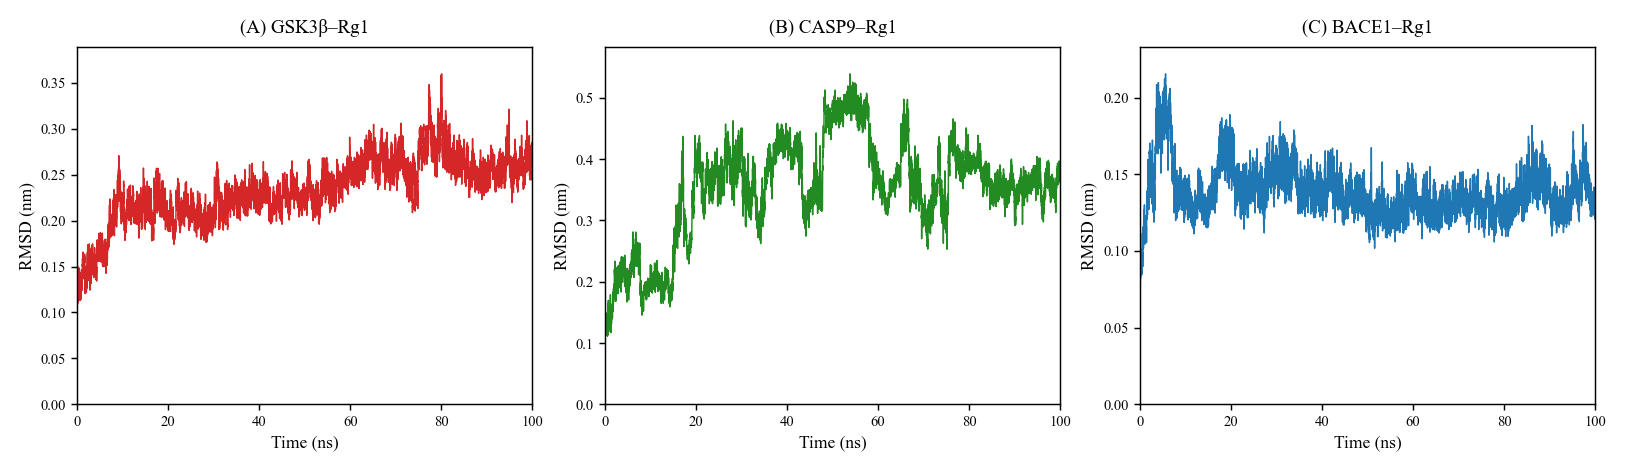

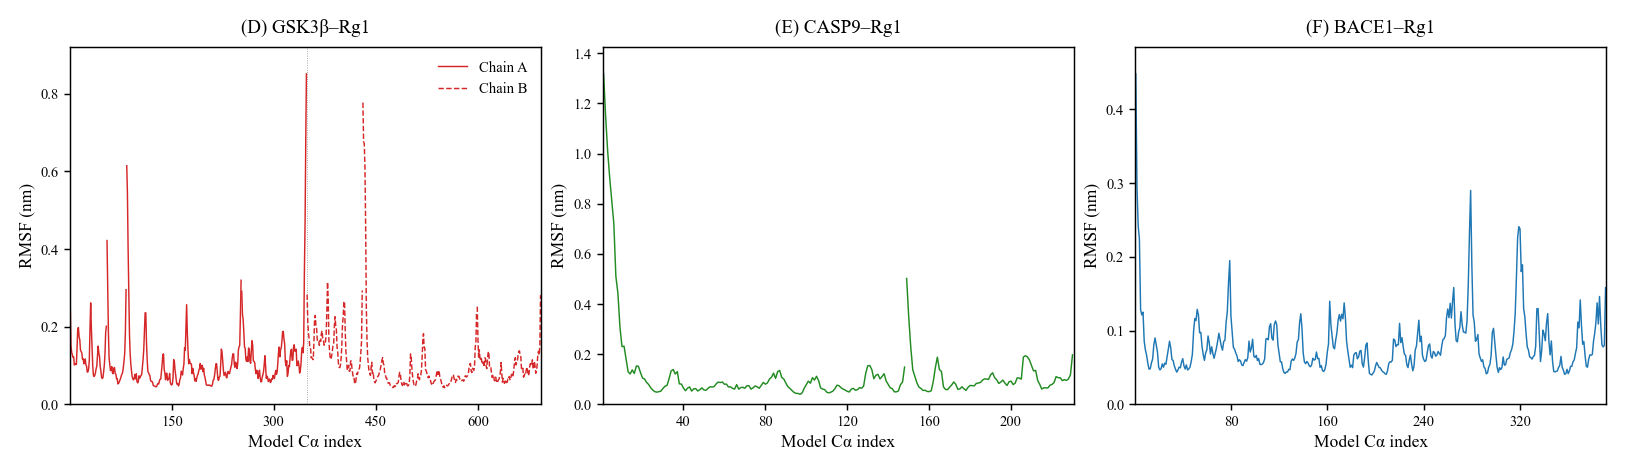

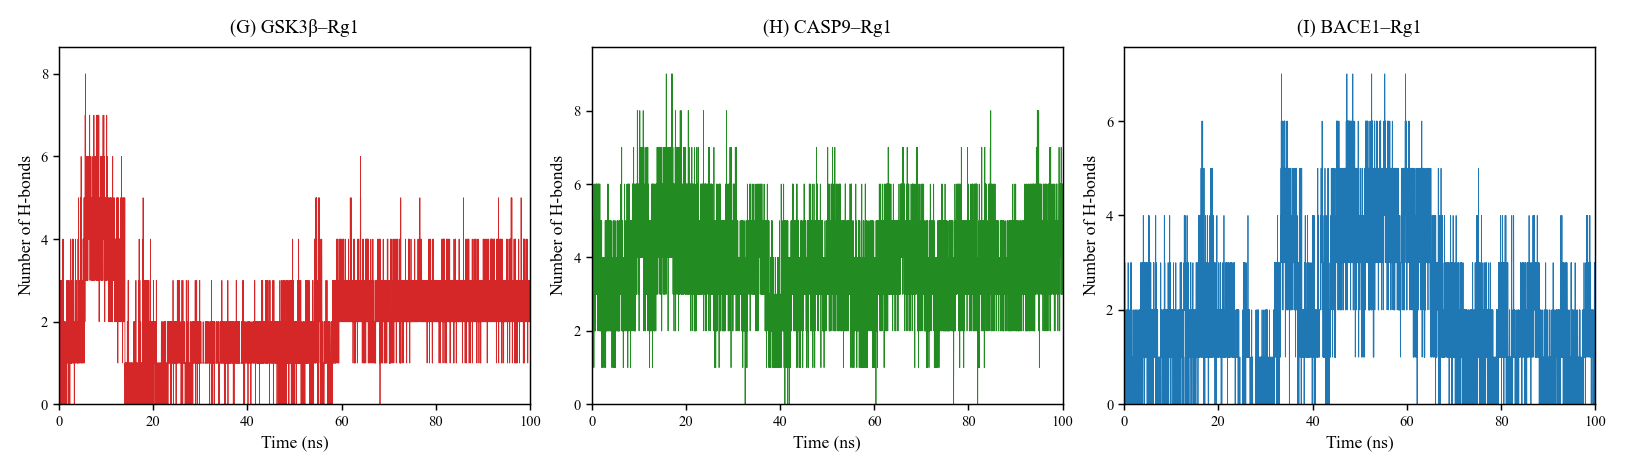

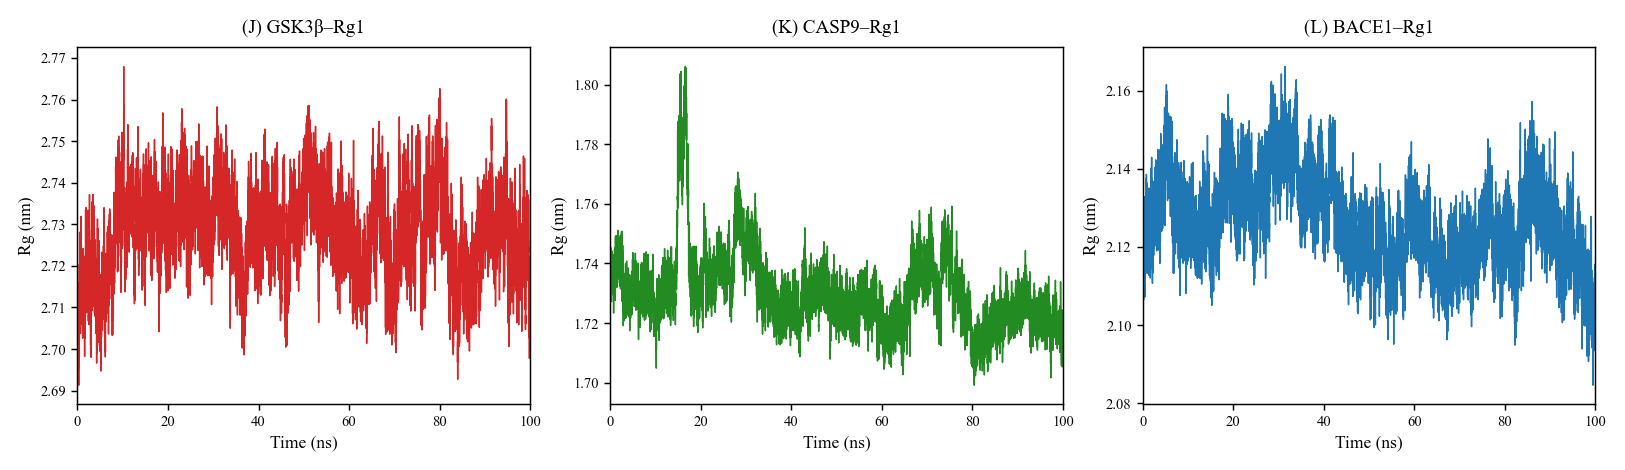

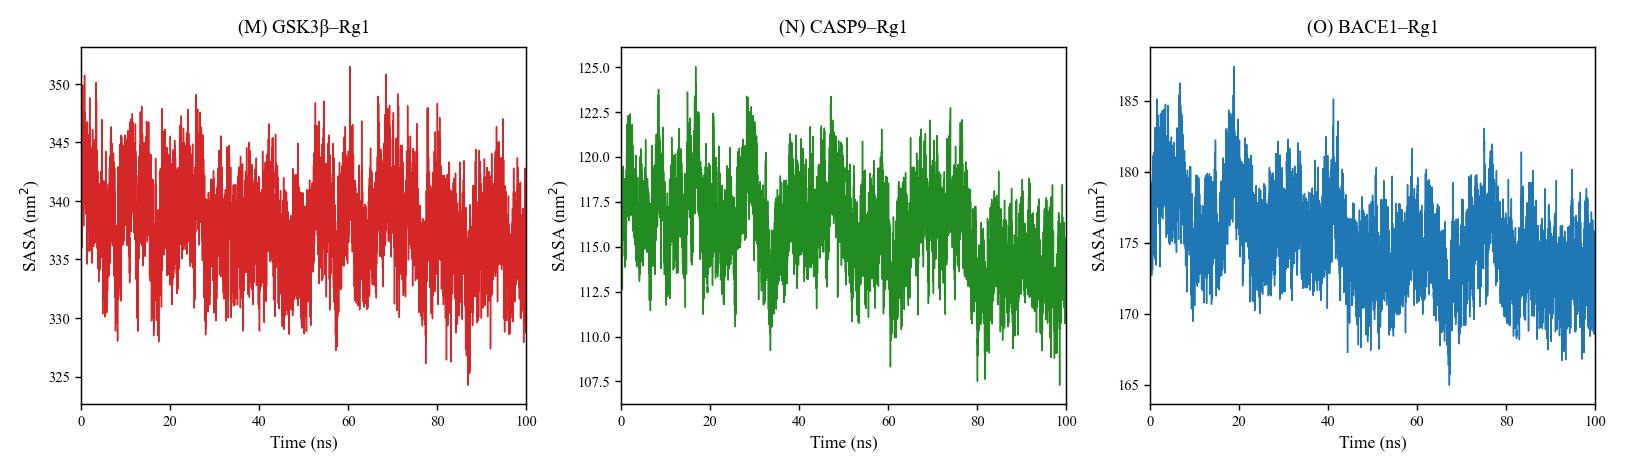

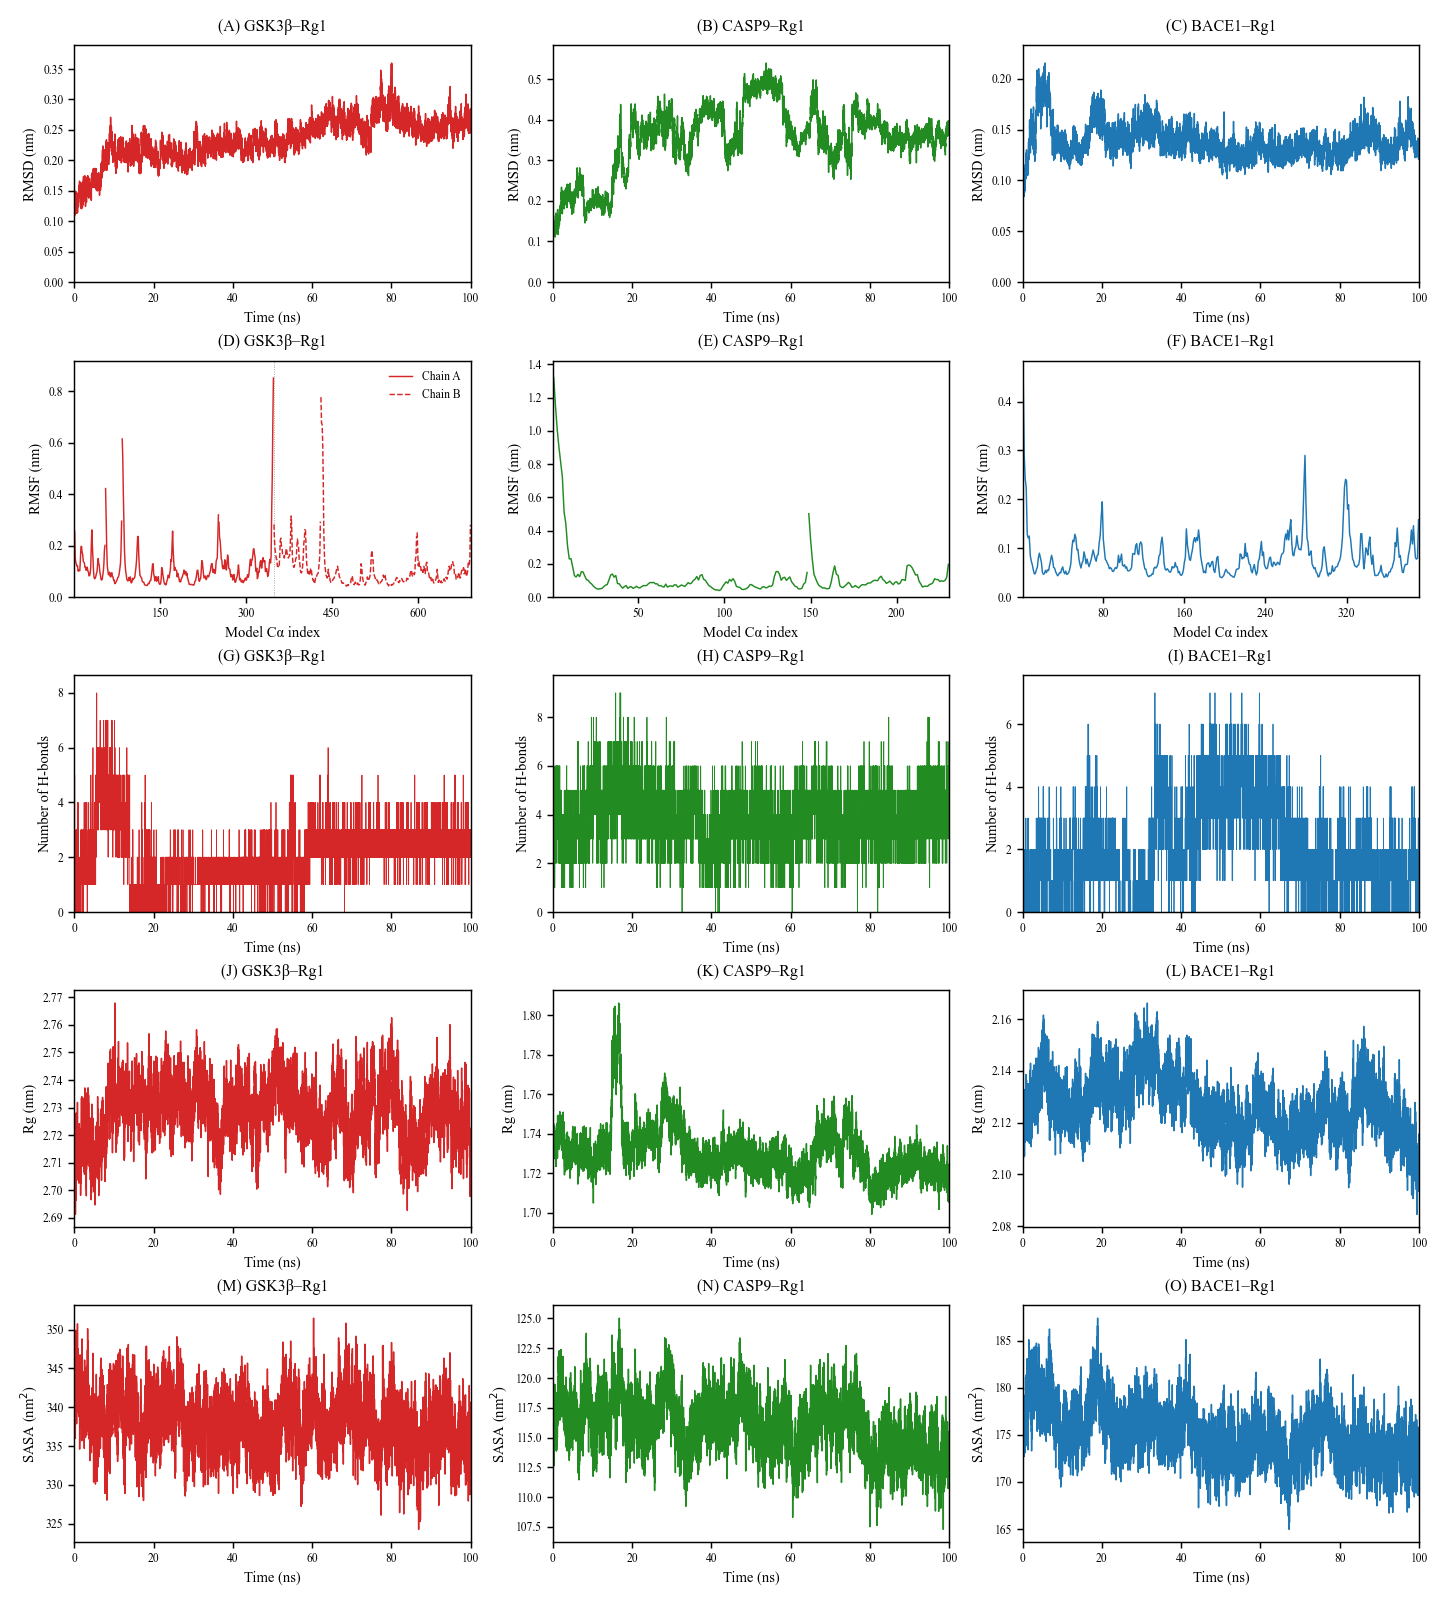

完成：15 张单图、5 张同指标组合图、1 张 A–O 总图。


In [8]:
for metric in METRICS:
    figure, axes = plt.subplots(1, 3, figsize=(15.2, 4.2), layout="constrained")
    for axis, system in zip(axes, SYSTEMS):
        draw_metric(axis, system, metric)
    save_figure(figure, OUT["overview"], f"Comparison_{METRIC_LABELS[metric]}", preview=SHOW_OVERVIEWS)

figure, axes = plt.subplots(5, 3, figsize=(13.5, 15.0), layout="constrained")
for row, metric in enumerate(METRICS):
    for col, system in enumerate(SYSTEMS):
        draw_metric(axes[row, col], system, metric, compact=True)
save_figure(figure, OUT["overview"], "All_metrics_A_to_O", preview=SHOW_OVERVIEWS)
print("完成：15 张单图、5 张同指标组合图、1 张 A–O 总图。", flush=True)


## 6. FEL 输入、计算与逐格核对

对等时间间隔的轨迹帧，使用

$$F(x,y)=-RT\ln\left[P(x,y)/P_{\max}\right],\quad R=0.008314462618\ \mathrm{kJ\,mol^{-1}\,K^{-1}}.$$

两种坐标分别是修正 RMSD 与蛋白 Rg，以及原 Cα PCA 的 PC1/PC2。PCA 的数值轴是集体坐标，不能把它的幅度直接当作单原子位移。每个体系的 PCA 基底不同。

默认 0–100 ns、50×50、无平滑时，新计算必须逐格匹配已核查网格。零计数网格始终保留为未知，不使用伪计数填成高能量平台。每套景观同时保存配对帧、原计数、原始计数能量和用于绘图的能量。


In [9]:
def read_pca_projection(path):
    record_input(path)
    datasets, rows = [], []
    for line in Path(path).read_text(encoding="utf-8").splitlines():
        text = line.strip()
        if not text or text.startswith(("#", "@")):
            continue
        if text == "&":
            if rows:
                datasets.append(np.asarray(rows, dtype=float))
                rows = []
        else:
            rows.append([float(value) for value in text.split()])
    if rows:
        datasets.append(np.asarray(rows, dtype=float))
    if len(datasets) == 1 and datasets[0].shape[1] >= 3:
        time, pc1, pc2 = datasets[0][:, :3].T
    elif len(datasets) == 2 and all(data.shape[1] == 2 for data in datasets) and datasets[0].shape == datasets[1].shape:
        np.testing.assert_allclose(datasets[0][:, 0], datasets[1][:, 0], atol=1e-7)
        time, pc1, pc2 = datasets[0][:, 0], datasets[0][:, 1], datasets[1][:, 1]
    else:
        raise ValueError(f"Unsupported PCA projection format: {path}")
    array = np.column_stack((time / 1000, pc1, pc2))
    if not np.isfinite(array).all() or not np.all(np.diff(array[:, 0]) > 0):
        raise ValueError("Non-finite PCA data or invalid timestamps")
    return pd.DataFrame(array, columns=["time_ns", "PC1_nm", "PC2_nm"])


def get_pca_path(system):
    if system in PCA_FILE_OVERRIDES:
        path = Path(PCA_FILE_OVERRIDES[system])
        if not path.is_file():
            raise FileNotFoundError(path)
        return path
    matches = list(QC_DIR.parent.glob(f"{system}_100ns_*/{system}/analysis/proj.xvg"))
    if len(matches) != 1:
        raise FileNotFoundError(f"Expected one PCA projection for {system}; set PCA_FILE_OVERRIDES explicitly")
    return matches[0]


def select_fel_time_window(frame):
    keep = frame.time_ns.ge(FEL_START_NS)
    if FEL_END_NS is not None:
        keep &= frame.time_ns.le(FEL_END_NS)
    selected = frame.loc[keep].copy()
    if len(selected) < 10:
        raise ValueError("Fewer than 10 frames in the FEL window")
    intervals = np.diff(selected.time_ns)
    if not np.allclose(intervals, intervals[0], atol=1e-8, rtol=1e-6):
        raise ValueError("FEL requires uniform time spacing or explicit statistical weights")
    return selected


def build_fel(system, mode):
    if mode == "RMSD_Rg":
        rmsd = DATA[(system, "RMSD")]
        rg = DATA[(system, "Radius_of_gyration")]
        np.testing.assert_allclose(rmsd.time_ns, rg.time_ns, atol=1e-8)
        paired = pd.DataFrame({"time_ns": rmsd.time_ns, "RMSD_nm": rmsd.value, "Rg_nm": rg.value})
        columns, labels = ("RMSD_nm", "Rg_nm"), ("RMSD (nm)", "Rg (nm)")
        reference_path = AUDIT_DIR / system / "FEL_RMSD_Rg_corrected_supported_grid.csv"
    elif mode == "PC1_PC2":
        paired = read_pca_projection(get_pca_path(system))
        np.testing.assert_allclose(paired.time_ns, DATA[(system, "RMSD")].time_ns, atol=1e-8)
        columns, labels = ("PC1_nm", "PC2_nm"), ("PC1 (nm)", "PC2 (nm)")
        reference_path = AUDIT_DIR / system / "FEL_PCA_supported_grid.csv"
    else:
        raise ValueError(f"Unknown FEL mode: {mode}")
    selected = select_fel_time_window(paired)
    bins = FEL_BINS[mode]
    if len(bins) != 2 or any(not isinstance(value, int) or value < 2 for value in bins):
        raise ValueError("FEL_BINS must contain two integers >= 2")
    sigma = float(FEL_SIGMA[mode])
    if sigma < 0:
        raise ValueError("Smoothing width must be non-negative")
    histogram, xe, ye = np.histogram2d(selected[columns[0]], selected[columns[1]], bins=bins)
    counts = histogram.T.astype(int)
    observed = counts > 0
    rt = 0.008314462618 * FEL_TEMPERATURE_K
    raw_energy = np.full(counts.shape, np.nan)
    raw_energy[observed] = -rt * np.log(counts[observed] / counts.max())
    effective_counts = gaussian_filter(counts.astype(float), sigma=sigma, mode="constant", cval=0) if sigma else counts.astype(float)
    energy = np.full(counts.shape, np.nan)
    energy[observed] = -rt * np.log(effective_counts[observed] / effective_counts[observed].max())
    support = observed & (counts >= FEL_MIN_BIN_COUNT)
    if not support.any():
        raise ValueError("No observed bins pass the display threshold")
    energy_max = float(energy[support].max())
    if FEL_ENERGY_MAX is not None and float(FEL_ENERGY_MAX) < energy_max - 1e-8:
        raise ValueError("FEL_ENERGY_MAX would clip observed values; use None or a larger value")
    scale_max = max(energy_max if FEL_ENERGY_MAX is None else float(FEL_ENERGY_MAX), 0.01)
    xx, yy = np.meshgrid((xe[:-1] + xe[1:]) / 2, (ye[:-1] + ye[1:]) / 2)
    reference_verified = False
    if tuple(bins) == (50, 50) and len(selected) == len(paired) and FEL_TEMPERATURE_K == 300.0:
        digest = record_input(reference_path)
        if VERIFY_INPUT_HASHES and digest != expected_hashes[reference_path.relative_to(AUDIT_DIR).as_posix()]:
            raise ValueError(f"Audited FEL checksum mismatch: {system} {mode}")
        reference = pd.read_csv(reference_path)
        np.testing.assert_array_equal(counts.ravel(), reference["count"].to_numpy())
        np.testing.assert_allclose(xx.ravel(), reference[columns[0]], atol=1e-9)
        np.testing.assert_allclose(yy.ravel(), reference[columns[1]], atol=1e-9)
        np.testing.assert_allclose(raw_energy.ravel(), reference.F_kJ_mol, atol=1e-8, equal_nan=True)
        reference_verified = True
    result = {"system": system, "mode": mode, "columns": columns, "labels": labels,
        "X": xx, "Y": yy, "xe": xe, "ye": ye, "count": counts, "observed": observed,
        "support": support, "raw_energy": raw_energy, "energy": energy,
        "masked_energy": np.ma.masked_where(~support, energy), "scale_max": scale_max,
        "selected_frames": selected, "input_frame_count": len(paired), "sigma": sigma,
        "reference_grid_verified": reference_verified}
    metadata = {"system": system, "mode": mode, "temperature_K": FEL_TEMPERATURE_K,
        "input_frames": len(paired), "selected_frames": len(selected), "excluded_by_window": len(paired) - len(selected),
        "start_ns": float(selected.time_ns.iloc[0]), "end_ns": float(selected.time_ns.iloc[-1]),
        "bins_xy": list(bins), "smoothing_sigma_bins": sigma, "minimum_raw_bin_count": FEL_MIN_BIN_COUNT,
        "unobserved_bins": int((~observed).sum()), "observed_bins": int(observed.sum()),
        "displayed_bins": int(support.sum()), "raw_supported_max_kJ_mol": float(np.nanmax(raw_energy)),
        "displayed_energy_max_kJ_mol": energy_max, "color_scale_max_kJ_mol": scale_max,
        "energy_cap_kJ_mol": None, "clipped_bins": 0, "fill_unobserved_bins": False,
        "reference_grid_verified": reference_verified, "colormap": FEL_COLORMAP,
        "elevation_deg": FEL_ELEVATION, "azimuth_deg": FEL_AZIMUTH, "projection_floor_kJ_mol": FEL_FLOOR_Z}
    grid = pd.DataFrame({columns[0]: xx.ravel(), columns[1]: yy.ravel(), "raw_frame_count": counts.ravel(),
        "raw_count_energy_kJ_mol": raw_energy.ravel(), "plot_energy_kJ_mol": energy.ravel(),
        "directly_sampled": observed.ravel(), "shown_in_figure": support.ravel()})
    stem = f"FEL_{system}_{mode}"
    save_csv(grid, OUT["data"] / f"{stem}_grid.csv")
    save_csv(selected, OUT["data"] / f"{stem}_paired_frames.csv")
    path = OUT["logs"] / f"{stem}_parameters.json"
    path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8")
    ARTIFACTS[str(path)] = {"type": "json", "bytes": path.stat().st_size}
    return result, metadata


FEL_RESULTS, FEL_METADATA = {}, []
for mode in FEL_MODES:
    for system in SYSTEMS:
        result, metadata = build_fel(system, mode)
        FEL_RESULTS[(system, mode)] = result
        FEL_METADATA.append(metadata)
fel_summary = pd.DataFrame(FEL_METADATA)
save_csv(fel_summary, OUT["data"] / "FEL_calculation_summary.csv")
display(fel_summary[["system", "mode", "selected_frames", "observed_bins", "raw_supported_max_kJ_mol", "reference_grid_verified"]])


,system,mode,selected_frames,observed_bins,raw_supported_max_kJ_mol,reference_grid_verified
0,GSK3beta-Rg1,RMSD_Rg,10001,1099,9.656087,True
1,CASP9-Rg1,RMSD_Rg,10001,1067,10.991851,True
2,BACE1-Rg1,RMSD_Rg,10001,949,11.110651,True
3,GSK3beta-Rg1,PC1_PC2,10001,1167,9.439051,True
4,CASP9-Rg1,PC1_PC2,10001,1269,10.961245,True
5,BACE1-Rg1,PC1_PC2,10001,1135,10.040591,True


## 7. FEL 2D 图

每个体系、每种坐标分别输出一张图，并为每种坐标输出一张三体系组合图。空网格为浅灰，颜色范围覆盖所有显示数据；色标按各景观单独计算，不把不同蛋白的能量高度直接解释成亲和力排序。


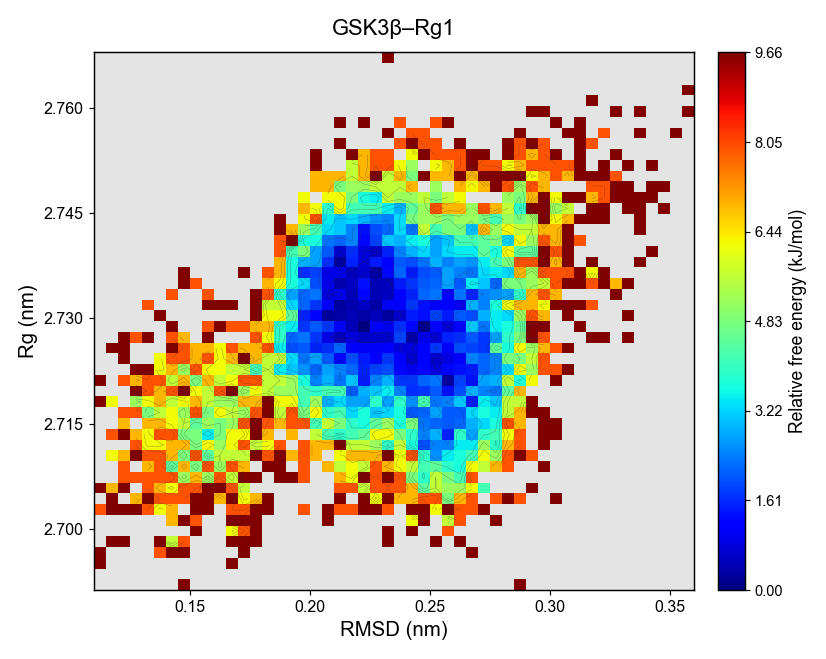

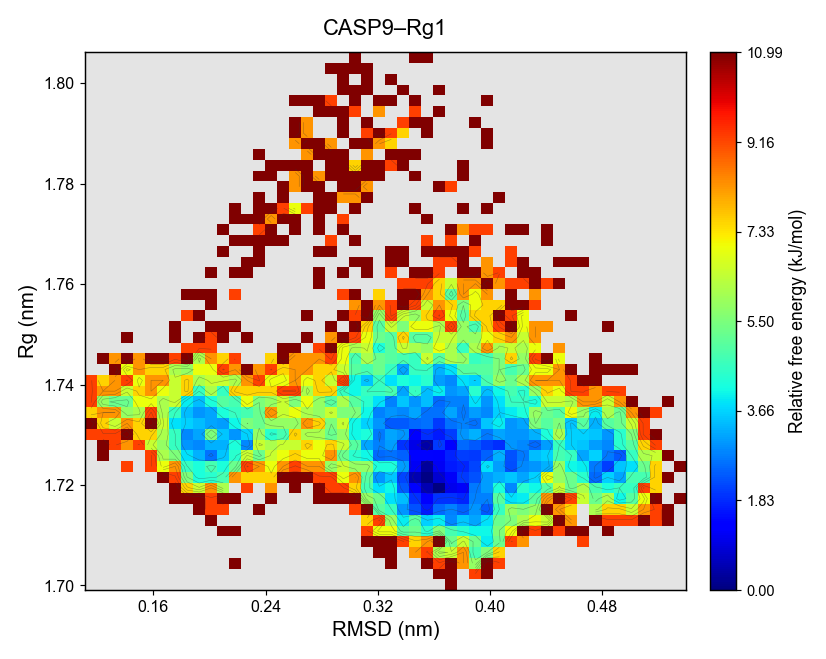

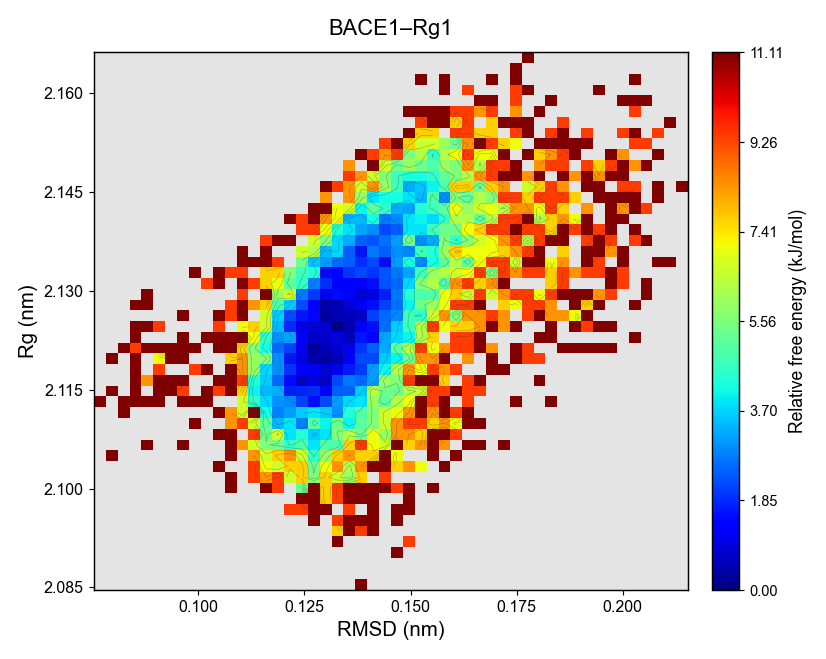

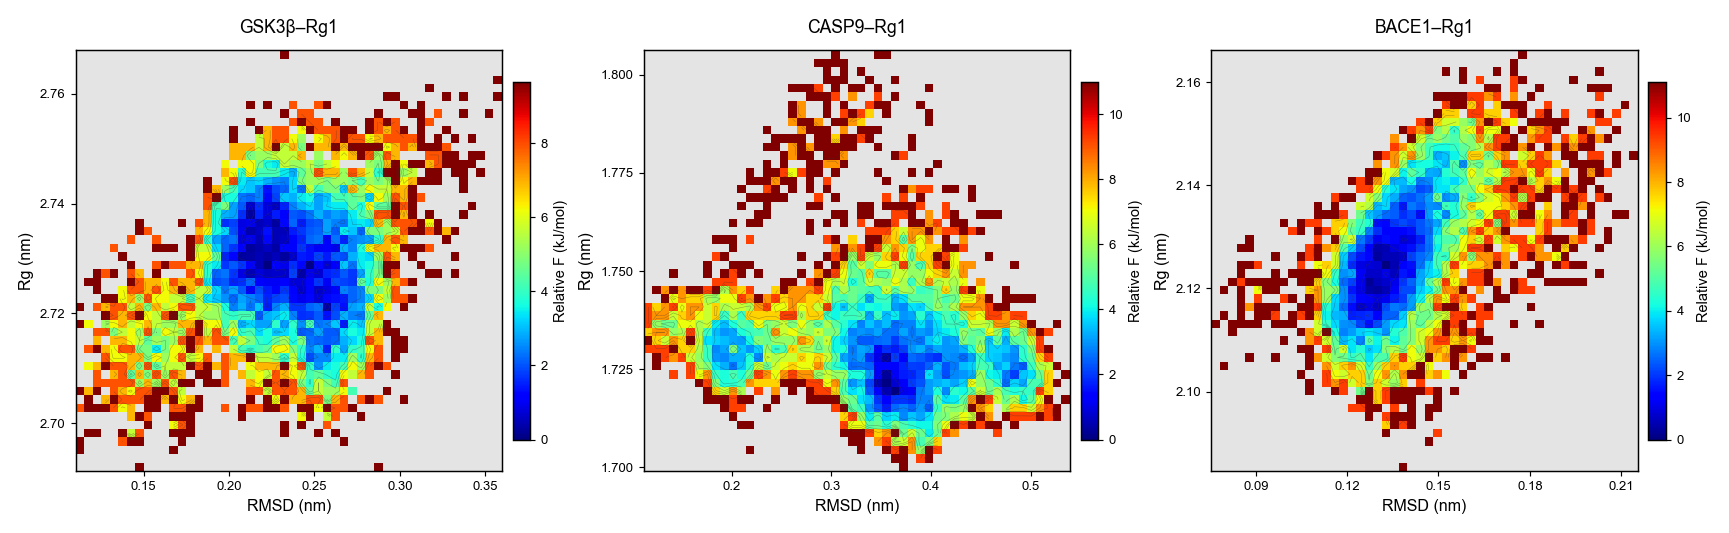

完成 FEL 2D：RMSD_Rg。


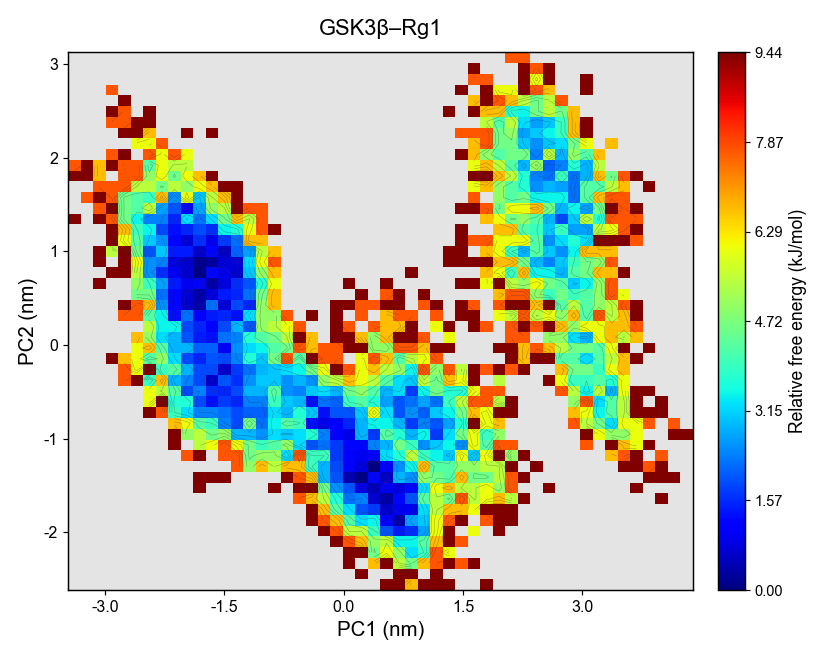

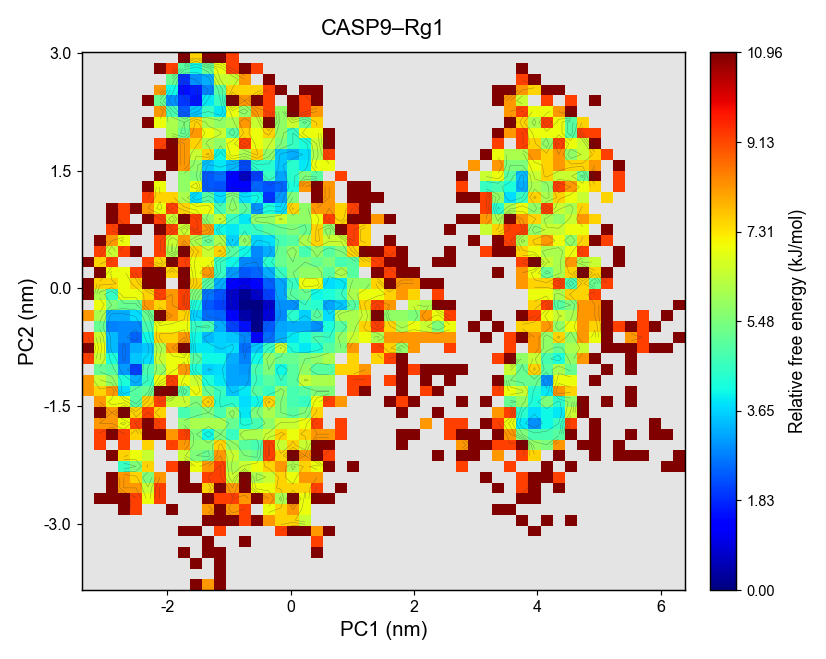

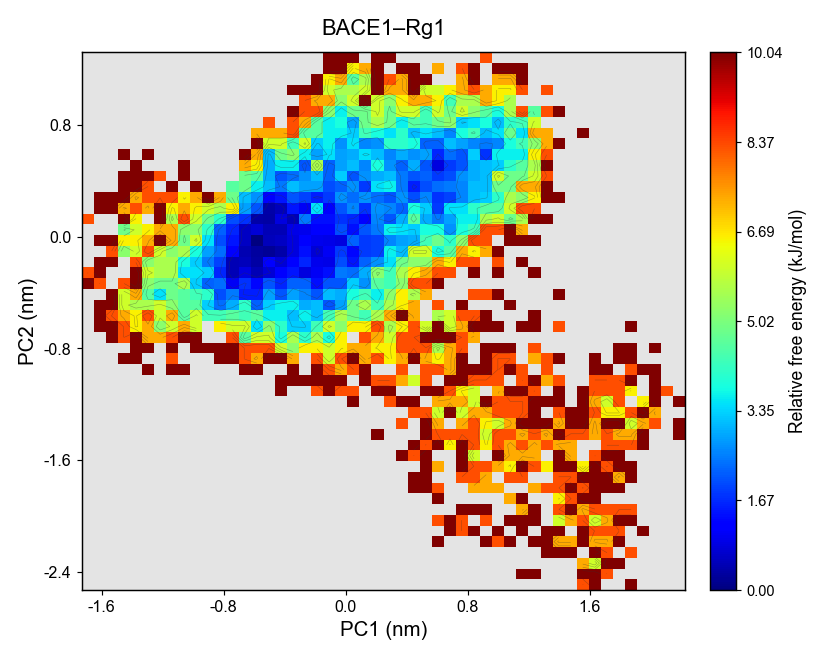

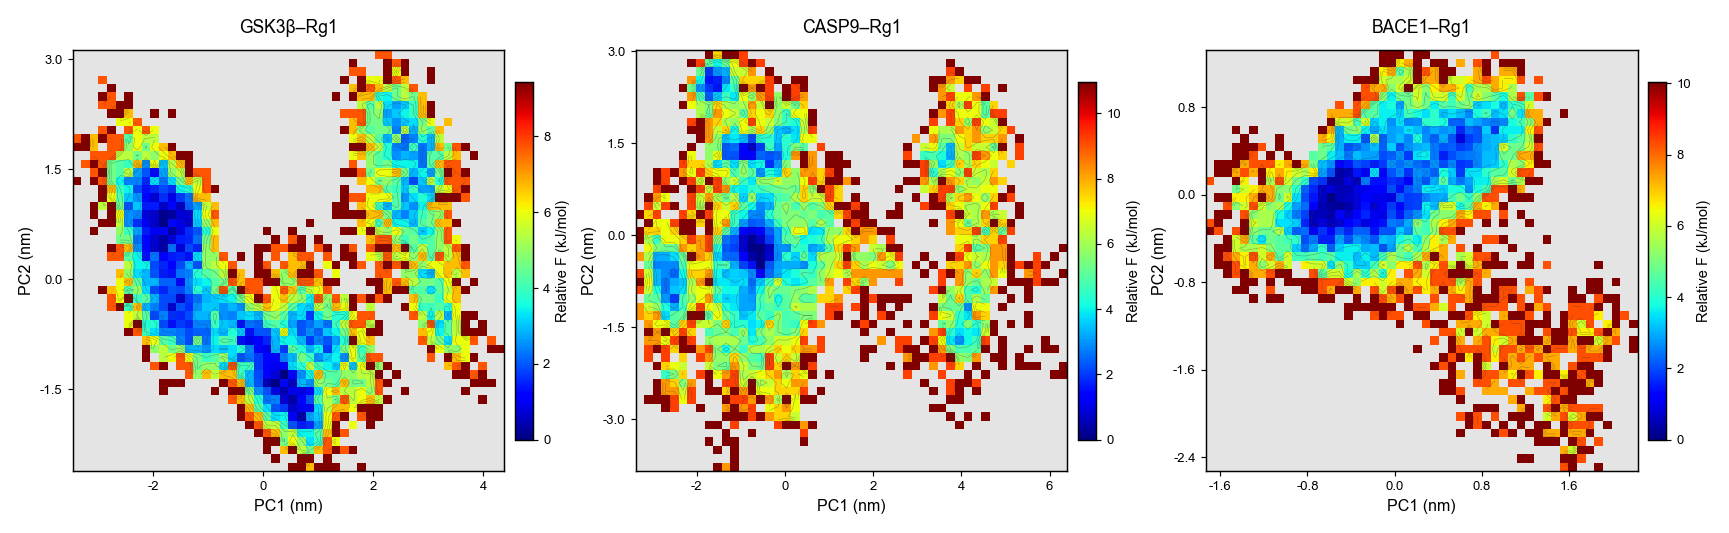

完成 FEL 2D：PC1_PC2。


In [10]:
def draw_fel_2d(axis, result, compact=False):
    axis.set_facecolor("#E4E4E4")
    norm = Normalize(vmin=0, vmax=result["scale_max"])
    cmap = mpl.colormaps[FEL_COLORMAP]
    mesh = axis.pcolormesh(result["xe"], result["ye"], result["masked_energy"],
                           cmap=cmap, norm=norm, shading="flat", rasterized=True)
    if result["energy"][result["support"]].max() > 0:
        axis.contour(result["X"], result["Y"], result["masked_energy"],
            levels=np.linspace(0, result["scale_max"], 13), colors="#333333", linewidths=0.35,
            alpha=0.45, corner_mask=False)
    axis.set_title(SYSTEM_LABELS[result["system"]], fontsize=12 if compact else 15, pad=12)
    axis.set_xlabel(result["labels"][0], fontsize=11 if compact else 14)
    axis.set_ylabel(result["labels"][1], fontsize=11 if compact else 14)
    axis.xaxis.set_major_locator(mpl.ticker.MaxNLocator(5 if compact else 6))
    axis.yaxis.set_major_locator(mpl.ticker.MaxNLocator(5 if compact else 6))
    axis.tick_params(labelsize=9 if compact else 11)
    return mesh


with mpl.rc_context({"font.family": FEL_FONT}):
    for mode in FEL_MODES:
        for system in SYSTEMS:
            result = FEL_RESULTS[(system, mode)]
            figure, axis = plt.subplots(figsize=FEL_FIGSIZE_2D, layout="constrained")
            mesh = draw_fel_2d(axis, result)
            colorbar = figure.colorbar(mesh, ax=axis, pad=0.04)
            colorbar.set_label("Relative free energy (kJ/mol)", fontsize=12)
            colorbar.set_ticks(np.linspace(0, result["scale_max"], 7))
            colorbar.ax.yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%.2f"))
            save_figure(figure, OUT["fel2d"], f"FEL_{system}_{mode}_2D", preview=SHOW_FEL)
        figure, axes = plt.subplots(1, 3, figsize=(16.2, 4.8), layout="constrained")
        for axis, system in zip(axes, SYSTEMS):
            mesh = draw_fel_2d(axis, FEL_RESULTS[(system, mode)], compact=True)
            colorbar = figure.colorbar(mesh, ax=axis, pad=0.025, shrink=0.85)
            colorbar.set_label("Relative F (kJ/mol)", fontsize=10)
            colorbar.ax.tick_params(labelsize=9)
        save_figure(figure, OUT["fel2d"], f"FEL_comparison_{mode}_2D", preview=SHOW_OVERVIEWS)
        print(f"完成 FEL 2D：{mode}。", flush=True)


## 8. FEL 3D 曲面与底部等高线

采用参考图的视角、jet 配色、底部等高线投影和浅色坐标面。只在四个网格顶点均有原始采样支持时连接曲面，避免跨越未采样区域补面；孤立的已采样网格以小点保留。

默认曲面未经平滑，局部粗糙和空洞反映有限采样。白色空区不是高能量平台。3D 曲面的最高值不等同于跨势阱的动力学能垒。


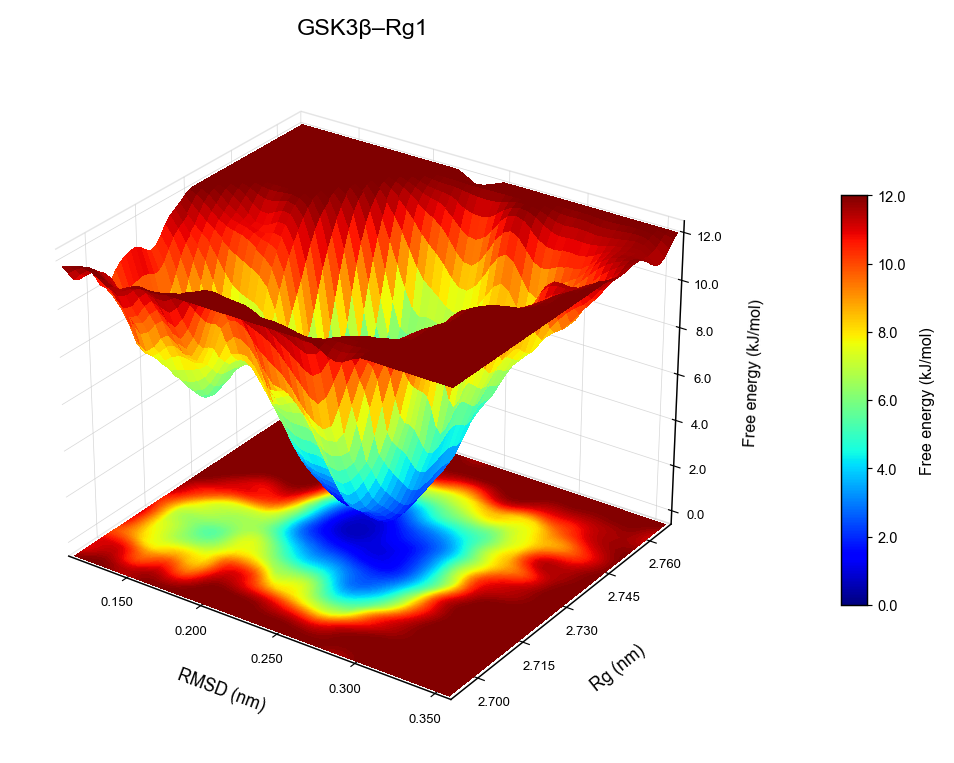

完成 FEL 3D 漏斗图：GSK3beta-Rg1 / RMSD_Rg


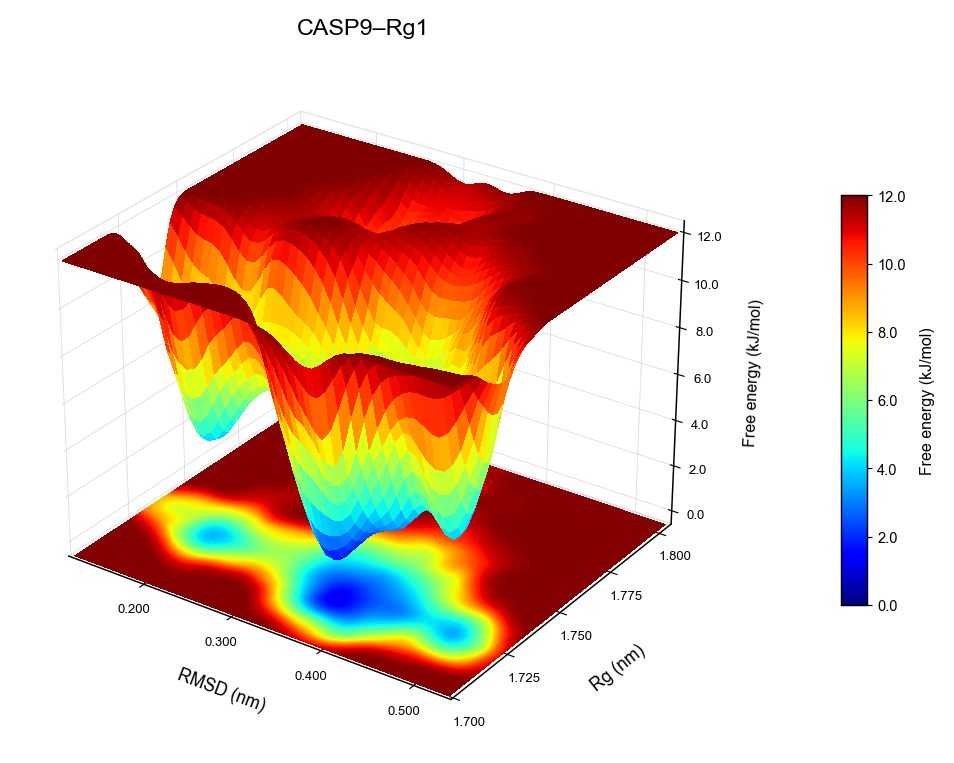

完成 FEL 3D 漏斗图：CASP9-Rg1 / RMSD_Rg


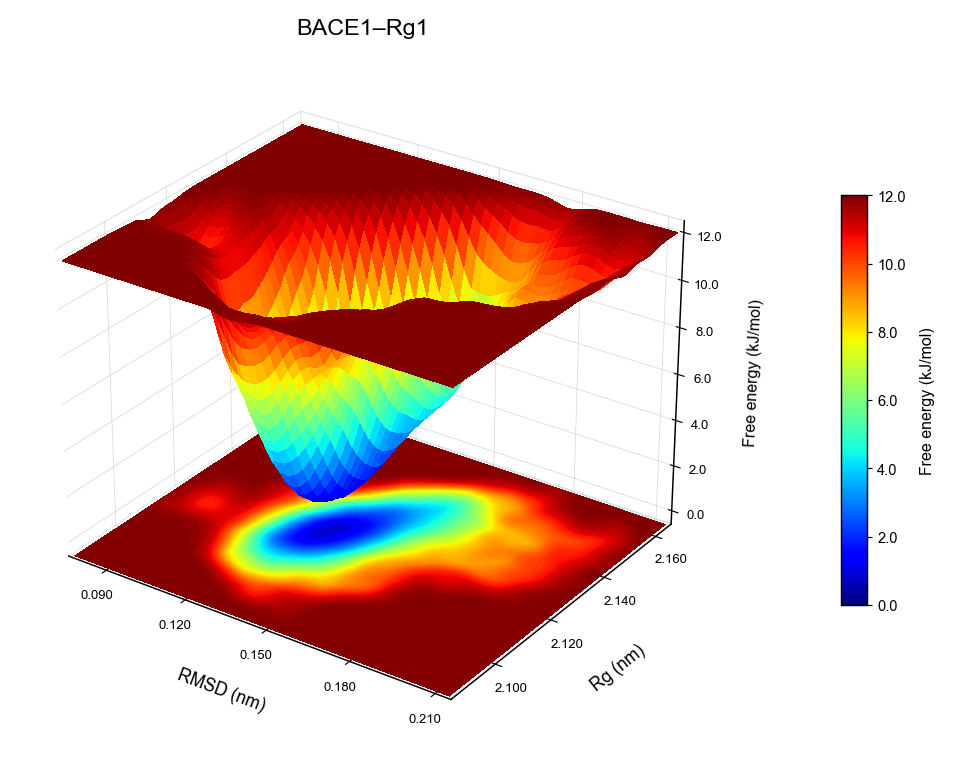

完成 FEL 3D 漏斗图：BACE1-Rg1 / RMSD_Rg


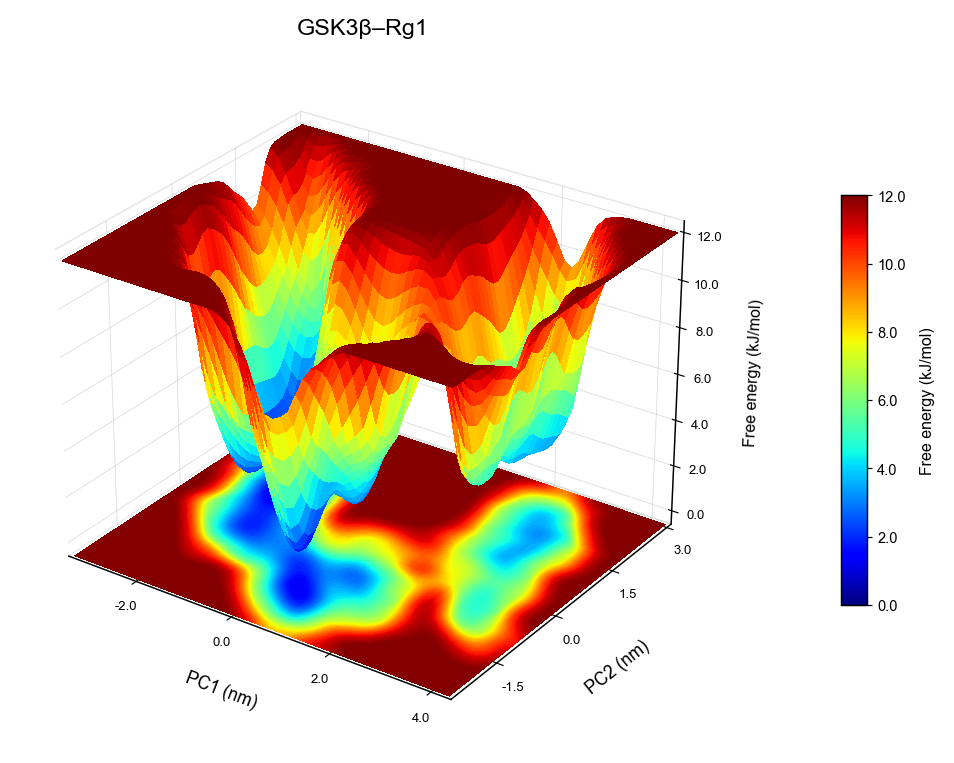

完成 FEL 3D 漏斗图：GSK3beta-Rg1 / PC1_PC2


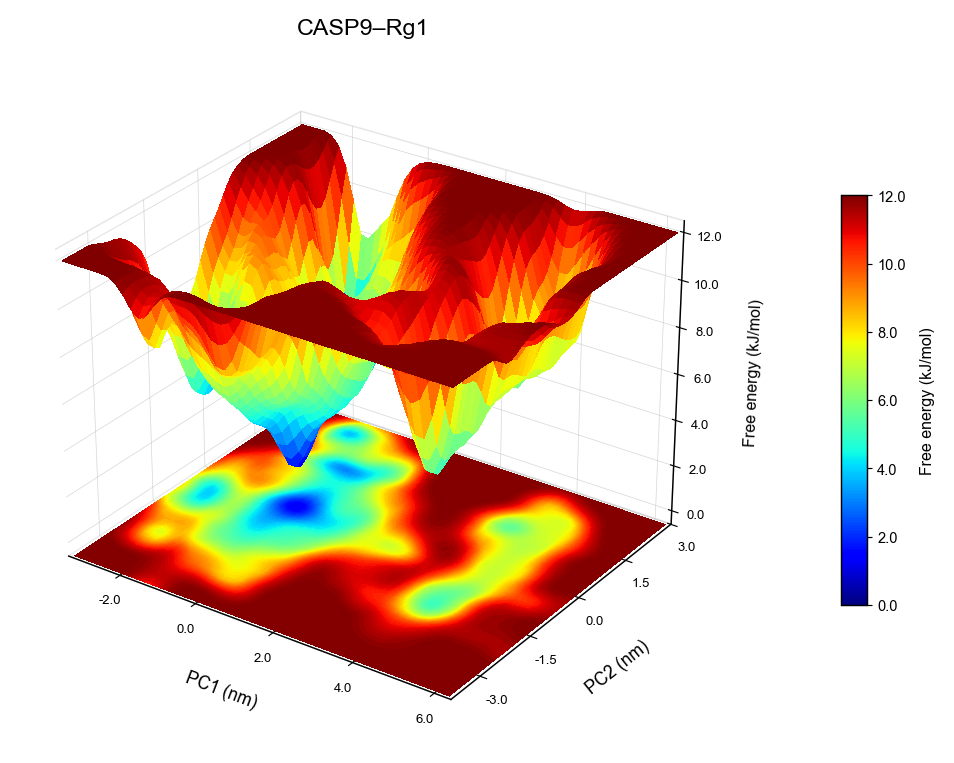

完成 FEL 3D 漏斗图：CASP9-Rg1 / PC1_PC2


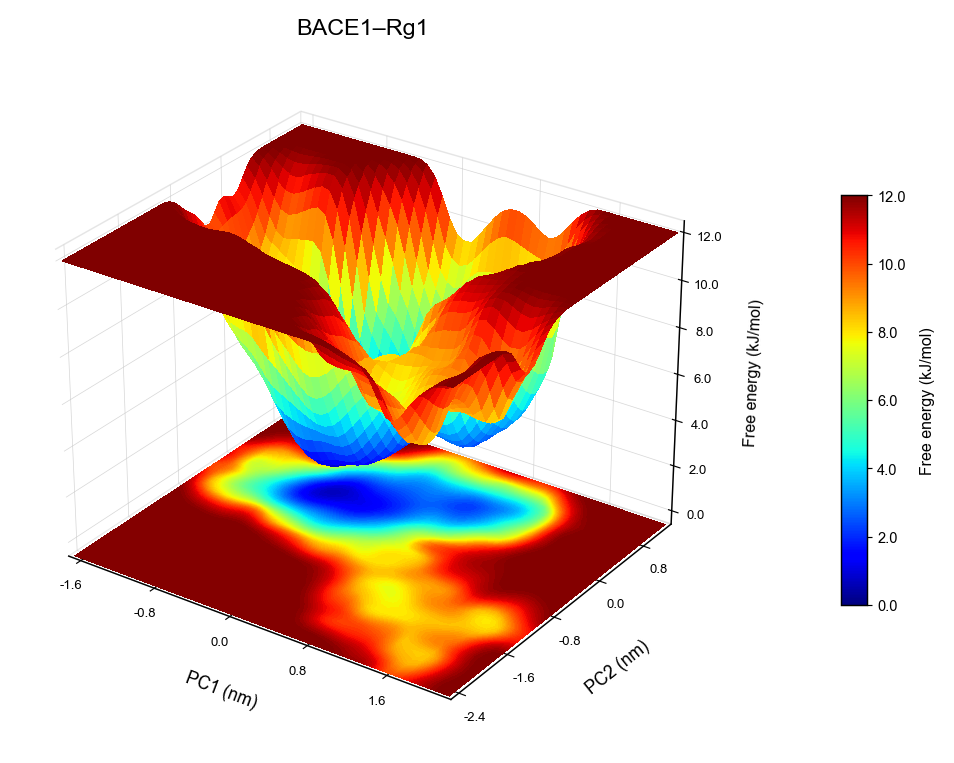

完成 FEL 3D 漏斗图：BACE1-Rg1 / PC1_PC2


In [11]:

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter, label
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# ==========================================
# 1. 自由能漏斗绘图参数
# ==========================================

FEL_FUNNEL_CMAP = "jet"  # 蓝→青→绿→黄→红
FEL_FUNNEL_CAP = 12.0  # 顶部红色平面高度 (kJ/mol)
FEL_FUNNEL_SIGMA = 1.4  # 自由能曲面平滑程度
FEL_FUNNEL_EDGE_SIGMA = 1.5  # 漏斗边缘平滑程度
FEL_FUNNEL_MAIN_ONLY = False  # True: 只保留最大连通能量盆地

FEL_FUNNEL_ELEV = 28
FEL_FUNNEL_AZIM = -55


# ==========================================
# 2. 构造连续漏斗形自由能曲面
# ==========================================

def build_funnel_surface(result, cap=12.0,
                         sigma=1.4, edge_sigma=1.5,
                         main_only=False):
    X = np.asarray(result["X"], dtype=float)
    Y = np.asarray(result["Y"], dtype=float)
    energy = np.asarray(result["energy"], dtype=float)

    support = np.asarray(result["support"], dtype=bool)
    support = support & np.isfinite(energy)

    cap = max(float(cap), float(result["scale_max"]))

    if not np.any(support):
        raise ValueError("该体系没有有效的自由能网格。")

    # 可选：仅保留最大的连通采样区域
    if main_only:
        regions, count = label(support)

        if count > 0:
            sizes = np.bincount(regions.ravel())
            sizes[0] = 0
            support = regions == np.argmax(sizes)

    # 将自由能限制在合理显示范围
    E = np.zeros_like(energy, dtype=float)
    E[support] = np.clip(energy[support], 0, cap)

    # --------------------------------------
    # 只对有效采样区进行加权平滑
    # 防止未采样区域中的填充值干扰真实低能区
    # --------------------------------------
    weights = support.astype(float)

    weighted_E = gaussian_filter(
        E * weights,
        sigma=sigma,
        mode="nearest"
    )

    smooth_weights = gaussian_filter(
        weights,
        sigma=sigma,
        mode="nearest"
    )

    E_smooth = np.divide(
        weighted_E,
        smooth_weights,
        out=np.full_like(E, cap),
        where=smooth_weights > 1e-8
    )

    # --------------------------------------
    # 将支持区域自然连接到顶部高能平面
    # --------------------------------------
    coverage = gaussian_filter(
        weights,
        sigma=edge_sigma,
        mode="nearest"
    )

    blend = np.clip(
        (coverage - 0.02) / 0.75,
        0.0,
        1.0
    )

    # 外部为 cap，内部保留平滑后的自由能
    Z = cap * (1.0 - blend) + E_smooth * blend

    Z = np.clip(Z, 0.0, cap)

    return X, Y, Z, support, cap


# ==========================================
# 3. 重新绘制三维自由能漏斗
# ==========================================

with mpl.rc_context({
    "font.family": FEL_FONT,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
}):
    for mode in FEL_MODES:
        for system in SYSTEMS:

            result = FEL_RESULTS[(system, mode)]

            X, Y, Z, support, cap = build_funnel_surface(
                result,
                cap=FEL_FUNNEL_CAP,
                sigma=FEL_FUNNEL_SIGMA,
                edge_sigma=FEL_FUNNEL_EDGE_SIGMA,
                main_only=FEL_FUNNEL_MAIN_ONLY
            )

            cmap = mpl.colormaps[FEL_FUNNEL_CMAP]
            norm = Normalize(vmin=0, vmax=cap)

            # ----------------------------------
            # 建立画布
            # ----------------------------------
            figure = plt.figure(
                figsize=FEL_FIGSIZE_3D,
                facecolor="white"
            )

            axis = figure.add_axes(
                [0.04, 0.08, 0.73, 0.84],
                projection="3d"
            )

            color_axis = figure.add_axes(
                [0.86, 0.25, 0.025, 0.50]
            )

            # ----------------------------------
            # ① 底部二维自由能投影
            # 使用完整连续曲面数据
            # 外部高能区显示为红色
            # ----------------------------------
            floor_z = -0.6

            levels = np.linspace(0, cap, 100)

            axis.contourf(
                X, Y, Z,
                zdir="z",
                offset=floor_z,
                levels=levels,
                cmap=cmap,
                norm=norm,
                alpha=1.0
            )

            # ----------------------------------
            # ② 绘制完整三维自由能漏斗
            # 红色高能平面 + 内部下凹曲面
            # ----------------------------------
            facecolors = cmap(norm(Z))

            axis.plot_surface(
                X, Y, Z,
                facecolors=facecolors,
                rstride=1,
                cstride=1,
                linewidth=0,
                edgecolor="none",
                antialiased=False,
                shade=False
            )

            # ----------------------------------
            # ③ 标题与坐标轴
            # ----------------------------------
            axis.set_title(
                SYSTEM_LABELS[system],
                pad=15,
                fontsize=16
            )

            axis.set_xlabel(
                result["labels"][0],
                labelpad=12,
                fontsize=12
            )

            axis.set_ylabel(
                result["labels"][1],
                labelpad=12,
                fontsize=12
            )

            axis.set_zlabel(
                "Free energy (kJ/mol)",
                labelpad=10,
                fontsize=11
            )

            axis.set_xlim(
                float(result["xe"][0]),
                float(result["xe"][-1])
            )

            axis.set_ylim(
                float(result["ye"][0]),
                float(result["ye"][-1])
            )

            axis.set_zlim(floor_z, cap * 1.04)

            axis.set_zticks(
                np.linspace(0, cap, 7)
            )

            axis.xaxis.set_major_locator(
                mpl.ticker.MaxNLocator(5)
            )

            axis.yaxis.set_major_locator(
                mpl.ticker.MaxNLocator(5)
            )

            decimals = 3 if mode == "RMSD_Rg" else 1

            axis.xaxis.set_major_formatter(
                mpl.ticker.FormatStrFormatter(
                    f"%.{decimals}f"
                )
            )

            axis.yaxis.set_major_formatter(
                mpl.ticker.FormatStrFormatter(
                    f"%.{decimals}f"
                )
            )

            axis.zaxis.set_major_formatter(
                mpl.ticker.FormatStrFormatter("%.1f")
            )

            axis.tick_params(
                axis="both",
                pad=2,
                labelsize=9
            )

            # ----------------------------------
            # ④ 视角与三维比例
            # ----------------------------------
            axis.view_init(
                elev=FEL_FUNNEL_ELEV,
                azim=FEL_FUNNEL_AZIM
            )

            axis.set_box_aspect(
                (1.15, 1.0, 0.85)
            )

            # 白色背景与浅灰网格
            for component in (
                    axis.xaxis,
                    axis.yaxis,
                    axis.zaxis
            ):
                component.pane.set_facecolor(
                    (1.0, 1.0, 1.0, 1.0)
                )

                component.pane.set_edgecolor(
                    (0.8, 0.8, 0.8, 1.0)
                )

                component._axinfo["grid"]["color"] = (
                    0.78, 0.78, 0.78, 0.7
                )

                component._axinfo["grid"]["linewidth"] = 0.5

            axis.grid(True)

            # ----------------------------------
            # ⑤ 色条
            # ----------------------------------
            colorbar = figure.colorbar(
                ScalarMappable(
                    norm=norm,
                    cmap=cmap
                ),
                cax=color_axis
            )

            colorbar.set_label(
                "Free energy (kJ/mol)",
                labelpad=10,
                fontsize=11
            )

            colorbar.set_ticks(
                np.linspace(0, cap, 7)
            )

            colorbar.ax.yaxis.set_major_formatter(
                mpl.ticker.FormatStrFormatter("%.1f")
            )

            # ----------------------------------
            # ⑥ 保存
            # ----------------------------------
            stem = f"FEL_{system}_{mode}_3D"

            save_figure(
                figure,
                OUT["fel3d"],
                stem,
                preview=SHOW_FEL
            )

            FIGURE_RECORDS[stem][
                "fully_supported_surface_quads"
            ] = int(
                np.sum(
                    support[:-1, :-1]
                    & support[1:, :-1]
                    & support[:-1, 1:]
                    & support[1:, 1:]
                )
            )

            print(
                f"完成 FEL 3D 漏斗图：{system} / {mode}",
                flush=True
            )



## 9. 导出检查与结果目录

本节核对导出文件数量、图片可读性、完整帧数、FEL 网格计数和空区掩膜，保存参数、版本、输入及输出校验值。默认共 35 组图件，每组 PNG/PDF/SVG；另有清洁源数据、统计表和 6 套 FEL 网格与配对帧。

所有图件可从下方清单定位。改变参数后重新运行全部单元格，会更新本输出目录下的同名文件；输入数据和旧参考文件不变。


In [12]:
from PIL import Image as PILImage

expected_figures = 15 + 5 + 1 + len(FEL_MODES) * (3 + 1 + 3)
if len(FIGURE_RECORDS) != expected_figures:
    raise AssertionError(f"Expected {expected_figures} figures, got {len(FIGURE_RECORDS)}")
checks = []
for stem, record in FIGURE_RECORDS.items():
    for extension in EXPORT_FORMATS:
        path = OUTPUT_DIR / record["directory"] / f"{stem}.{extension}"
        if not path.is_file() or path.stat().st_size < 1000:
            raise AssertionError(f"Missing or empty figure: {path}")
        row = {"figure": stem, "format": extension, "relative_path": path.relative_to(OUTPUT_DIR).as_posix(), "bytes": path.stat().st_size}
        if extension == "png":
            with PILImage.open(path) as rendered:
                rendered.load()
                thumbnail = rendered.convert("RGB")
                thumbnail.thumbnail((300, 300))
                pixels = np.asarray(thumbnail)
                if float(pixels.std()) < 2 or np.mean(np.any(pixels < 245, axis=2)) < 0.01:
                    raise AssertionError(f"Blank figure: {path.name}")
                row.update(width_px=rendered.width, height_px=rendered.height)
        checks.append(row)
for result in FEL_RESULTS.values():
    if int(result["count"].sum()) != len(result["selected_frames"]):
        raise AssertionError("FEL frame count mismatch")
    if not np.isnan(result["energy"][~result["observed"]]).all():
        raise AssertionError("Unobserved FEL cells have invented energies")

figure_index = pd.DataFrame(checks)
save_csv(figure_index, OUT["logs"] / "figure_index.csv")
parameters = {
    "run_started_at": RUN_STARTED_AT, "run_finished_at": datetime.now().astimezone().isoformat(),
    "qc_directory": str(QC_DIR), "data_directory": str(DATA_DIR), "output_directory": str(OUTPUT_DIR),
    "systems": list(SYSTEMS), "figure_groups": len(FIGURE_RECORDS), "figure_files": len(checks),
    "input_hash_verification": VERIFY_INPUT_HASHES, "expected_trajectory_frames": EXPECTED_FRAMES,
    "time_axis_unit": TIME_AXIS_UNIT, "line_font": LINE_FONT, "fel_font": FEL_FONT,
    "system_colors": COLORS, "line_width": LINE_WIDTH, "hbond_line_width": HBOND_LINE_WIDTH,
    "dpi": DPI, "formats": list(EXPORT_FORMATS), "summary_sd_ddof": 1,
    "terminal_window_start_ns": TAIL_START_NS, "terminal_window_is_proven_equilibrium": False,
    "fel_calculations": FEL_METADATA, "figures": FIGURE_RECORDS, "inputs": INPUT_FILES,
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
        "scipy": scipy.__version__, "matplotlib": mpl.__version__},
    "cautions": ["Single trajectories; frames are temporally correlated, not independent replicate runs.",
        "RMSF uses full-trajectory C-alpha fluctuations and a sequential model index with a source identity map.",
        "SASA is protein-only; composition differs among systems.",
        "CASP9 PC1/PC2 are dominated by the flexible N-terminal tail.",
        "Unobserved FEL cells are masked; relative FEL ranges are not kinetic barriers or binding free energies.",
        "Existing template mutations, missing loops and ligand-pose migration remain interpretation limits."],
}
parameter_path = OUT["logs"] / "run_parameters.json"
parameter_path.write_text(json.dumps(parameters, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8")
ARTIFACTS[str(parameter_path)] = {"type": "json", "bytes": parameter_path.stat().st_size}
artifact_rows = []
for filename, info in sorted(ARTIFACTS.items()):
    path = Path(filename)
    artifact_rows.append({"path": path.relative_to(OUTPUT_DIR).as_posix(), "type": info["type"],
        "bytes": path.stat().st_size, "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
delivery_path = OUT["logs"] / "output_manifest.json"
delivery_path.write_text(json.dumps({"status": "VERIFIED", "figure_groups": len(FIGURE_RECORDS),
    "figure_files": len(checks), "artifacts": artifact_rows}, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
display(figure_index[["figure", "format", "relative_path"]])
display(Markdown(f"**完成：{len(FIGURE_RECORDS)} 组图件，{len(checks)} 个图片文件。** 输出目录：`{OUTPUT_DIR}`"))


,figure,format,relative_path
0,A_RMSD_GSK3beta-Rg1,png,01_单项指标/A_RMSD_GSK3beta-Rg1.png
1,A_RMSD_GSK3beta-Rg1,pdf,01_单项指标/A_RMSD_GSK3beta-Rg1.pdf
2,A_RMSD_GSK3beta-Rg1,svg,01_单项指标/A_RMSD_GSK3beta-Rg1.svg
3,B_RMSD_CASP9-Rg1,png,01_单项指标/B_RMSD_CASP9-Rg1.png
4,B_RMSD_CASP9-Rg1,pdf,01_单项指标/B_RMSD_CASP9-Rg1.pdf
...,...,...,...
100,FEL_CASP9-Rg1_PC1_PC2_3D,pdf,04_FEL_3D/FEL_CASP9-Rg1_PC1_PC2_3D.pdf
101,FEL_CASP9-Rg1_PC1_PC2_3D,svg,04_FEL_3D/FEL_CASP9-Rg1_PC1_PC2_3D.svg
102,FEL_BACE1-Rg1_PC1_PC2_3D,png,04_FEL_3D/FEL_BACE1-Rg1_PC1_PC2_3D.png
103,FEL_BACE1-Rg1_PC1_PC2_3D,pdf,04_FEL_3D/FEL_BACE1-Rg1_PC1_PC2_3D.pdf


**完成：35 组图件，105 个图片文件。** 输出目录：`C:\Users\zengh\Desktop\生信文章\shengxin\文章二\分子动力学模拟\模拟结果\MD_QC_20261110\更新后图片结果`

## 10. 调整参数和解释边界

| 目标 | 修改位置 |
| --- | --- |
| 指定数据所在 QC 文件夹 | `QC_DIR_OVERRIDE` |
| 切换指标时间轴单位 | `TIME_AXIS_UNIT` |
| 调整指标线宽、字体、体系颜色 | `LINE_WIDTH`、`HBOND_LINE_WIDTH`、`LINE_FONT`、`COLORS` |
| 调整 FEL 统计区间和分箱 | `FEL_START_NS`、`FEL_END_NS`、`FEL_BINS` |
| 参考图的可选平滑外观 | `FEL_SIGMA["RMSD_Rg"] = 1.2`；原始计数与未平滑估计仍保存 |
| 改变 FEL 配色或 3D 视角 | `FEL_COLORMAP`、`FEL_ELEVATION`、`FEL_AZIMUTH` |
| 改变导出分辨率和格式 | `DPI`、`EXPORT_FORMATS` |
| 查看每个图件的输入和参数 | `06_运行记录/run_parameters.json`、各 FEL 的参数 JSON |

默认没有任意减去 RMSD 基线、截断高峰、填充空区域或只保留好看时间段。高 RMSF 可能反映末端/断链柔性；蛋白较稳定不等于 Rg1 保持初始结合姿势。CASP9 的 PCA 受 N 端尾部主导，BACE1 配体已有明显姿势变化，当前三条单轨迹均不能仅凭 FEL 的形状宣称自由能已收敛。

2D/3D 采用同一套网格和能量数值，导出网格含真实帧计数及显示掩膜。完整的模型和轨迹限制见同目录之前的核查报告。
